









# ⚽ Analyse Exploratoire et Descriptive
## Premier League Anglaise — Saison 2018/2019

---

| | |
|---|---|
| **Dataset** | England Premier League Match Stats 2018–2019 |
| **Domaine** | Sport / Football |
| **Objectif** | Analyse statistique exploratoire, descriptive et multivariée |
| **Outil** | Python (pandas, matplotlib, seaborn, scipy, mlxtend) |

---

### 📋 Plan du Notebook

1. [Importation des données](#1)
2. [Nettoyage des données](#2)
3. [Statistique descriptive univariée](#3)
4. [Analyse de la fiabilité (Cronbach)](#4)
5. [Statistique descriptive bivariée](#5)
6. [Statistique descriptive multivariée](#6)
7. [Règles d'Association](#7)
8. [Apprentissage Supervisé  — Régression Logistique](#8)
9. [Apprentissage Non Supervisé  — CLUSTERING K-MEANS](#9)

### ⚙️ Bibliothèques nécessaires

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr, f_oneway
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
import warnings

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 110

print('✅ Bibliothèques chargées avec succès')

✅ Bibliothèques chargées avec succès


---
<a id='1'></a>
## 1. 📥 Importation des Données

Le dataset contient les statistiques de **380 matchs** disputés durant la saison 2018/2019 de la Premier League anglaise.  
Il couvre des variables liées aux buts, tirs, possession, cartons, corners, affluence, et données pré-match (xG, cotes, PPG).

In [ ]:
# The dataset is read from the local data/ folder (see README for the download link)
DATA_PATH = 'data/england-premier-league-matches-2018-to-2019-stats.csv'

In [ ]:
df = pd.read_csv(DATA_PATH)

print(f'Dimensions           : {df.shape[0]} lignes × {df.shape[1]} colonnes')
print(f'Équipes              : {df["home_team_name"].nunique()}')
print(f'Journées (Game Week) : {df["Game Week"].nunique()}')
print(f'Statuts de match     : {df["status"].value_counts().to_dict()}')

Dimensions           : 380 lignes × 66 colonnes
Équipes              : 20
Journées (Game Week) : 38
Statuts de match     : {'complete': 380}


In [ ]:
# Aperçu des premières lignes
df.head(5)

,timestamp,date_GMT,status,attendance,home_team_name,away_team_name,referee,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),...,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no,stadium_name
0,1533927600,Aug 10 2018 - 7:00pm,complete,74439,Manchester United,Leicester City,Andre Marriner,1,0.0,0.0,...,1.37,4.98,9.81,1.33,2.00,3.60,7.50,2.05,1.69,Old Trafford (Manchester)
1,1533987000,Aug 11 2018 - 11:30am,complete,51749,Newcastle United,Tottenham Hotspur,Martin Atkinson,1,0.0,0.0,...,4.51,3.77,1.84,1.31,1.95,3.50,5.75,1.83,1.87,St. James' Park (Newcastle upon Tyne)
2,1533996000,Aug 11 2018 - 2:00pm,complete,10353,AFC Bournemouth,Cardiff City,Kevin Friend,1,0.0,0.0,...,2.03,3.51,3.96,1.31,1.95,3.45,6.70,1.83,1.83,Vitality Stadium (Bournemouth- Dorset)
3,1533996000,Aug 11 2018 - 2:00pm,complete,24821,Fulham,Crystal Palace,Mike Dean,1,0.0,0.0,...,2.31,3.44,3.26,1.28,1.87,3.20,7.00,1.71,2.00,Craven Cottage (London)
4,1533996000,Aug 11 2018 - 2:00pm,complete,24121,Huddersfield Town,Chelsea,Chris Kavanagh,1,0.0,0.0,...,7.47,4.27,1.51,1.29,1.91,3.30,6.95,2.00,1.71,John Smith's Stadium (Huddersfield- West Yorks...


In [ ]:
# Résumé des types
type_summary = df.dtypes.value_counts().rename_axis('Type').reset_index(name='Nombre de colonnes')
type_summary['Type'] = type_summary['Type'].astype(str)
print(type_summary.to_string(index=False))

   Type  Nombre de colonnes
  int64                  38
float64                  20
 object                   8


In [ ]:
df.describe()

,timestamp,attendance,Game Week,Pre-Match PPG (Home),Pre-Match PPG (Away),home_ppg,away_ppg,home_team_goal_count,away_team_goal_count,total_goal_count,...,average_cards_per_match_pre_match,odds_ft_home_team_win,odds_ft_draw,odds_ft_away_team_win,odds_ft_over15,odds_ft_over25,odds_ft_over35,odds_ft_over45,odds_btts_yes,odds_btts_no
count,3.800000e+02,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,...,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000,380.000000
mean,1.546145e+09,38186.847368,19.500000,1.480895,1.167632,1.615500,1.198000,1.568421,1.252632,2.821053,...,3.354763,3.219421,4.471316,5.381816,1.261000,1.821474,3.101158,5.897763,1.842316,1.908868
std,6.877351e+06,16720.334767,10.980313,0.831446,0.761209,0.590587,0.534085,1.312836,1.180031,1.601312,...,1.169849,2.962683,1.906924,5.540953,0.107498,0.312900,0.833400,2.032061,0.214528,0.228041
min,1.533928e+09,9980.000000,1.000000,0.000000,0.000000,0.470000,0.260000,0.000000,0.000000,0.000000,...,0.000000,1.070000,2.900000,1.120000,1.050000,1.200000,1.540000,2.300000,1.430000,1.380000
25%,1.540656e+09,25034.750000,10.000000,1.000000,0.630000,1.210000,0.840000,1.000000,0.000000,2.000000,...,2.922500,1.570000,3.350000,2.300000,1.180000,1.585000,2.450000,4.437500,1.690000,1.740000
50%,1.546018e+09,31948.000000,19.500000,1.470000,1.075000,1.475000,1.160000,1.000000,1.000000,3.000000,...,3.500000,2.300000,3.750000,3.350000,1.250000,1.770000,2.950000,5.500000,1.830000,1.890000
75%,1.551541e+09,53282.750000,29.000000,2.062500,1.610000,1.917500,1.542500,2.000000,2.000000,4.000000,...,4.000000,3.350000,4.850000,6.312500,1.330000,2.000000,3.600000,7.050000,1.962500,2.050000
max,1.557670e+09,81332.000000,38.000000,3.000000,3.000000,2.840000,2.320000,6.000000,6.000000,8.000000,...,8.000000,22.000000,15.750000,42.750000,1.570000,2.750000,5.650000,15.000000,2.800000,2.550000


---
<a id='2'></a>
## 2. 🧹 Nettoyage des Données

Cette étape comprend :
- La détection et traitement des **valeurs manquantes**
- La détection des **doublons**
- La vérification des **valeurs aberrantes** (outliers)
- La **création de variables dérivées** utiles pour l'analyse

In [ ]:
# --- Valeurs manquantes ---
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Valeurs manquantes': missing, 'Pourcentage (%)': missing_pct})
missing_df = missing_df[missing_df['Valeurs manquantes'] > 0].sort_values('Valeurs manquantes', ascending=False)

print(f'Colonnes avec valeurs manquantes : {len(missing_df)}')
print(missing_df)

Colonnes avec valeurs manquantes : 2
                        Valeurs manquantes  Pourcentage (%)
away_team_goal_timings                 119            31.32
home_team_goal_timings                  88            23.16


In [ ]:
# --- Doublons ---
doublons = df.duplicated().sum()
print(f'Nombre de lignes dupliquées : {doublons}')
if doublons == 0:
    print('✅ Aucun doublon détecté.')

Nombre de lignes dupliquées : 0
✅ Aucun doublon détecté.


In [ ]:
# --- Détection des outliers via Z-score ---
num_cols = [
    'home_team_goal_count', 'away_team_goal_count',
    'home_team_shots', 'away_team_shots',
    'home_team_possession', 'attendance',
    'home_team_yellow_cards', 'away_team_yellow_cards'
]

z_scores = np.abs(stats.zscore(df[num_cols]))
outlier_mask = (z_scores > 3).any(axis=1)
print(f'Lignes avec au moins un outlier (|Z| > 3) : {outlier_mask.sum()}')
df[outlier_mask][['home_team_name','away_team_name'] + num_cols]

Lignes avec au moins un outlier (|Z| > 3) : 13


,home_team_name,away_team_name,home_team_goal_count,away_team_goal_count,home_team_shots,away_team_shots,home_team_possession,attendance,home_team_yellow_cards,away_team_yellow_cards
14,West Ham United,AFC Bournemouth,1,2,9,9,61,56888,6,2
17,Manchester City,Huddersfield Town,6,1,24,4,76,54021,0,2
52,Cardiff City,Manchester City,0,5,3,15,21,32321,1,1
77,Fulham,Arsenal,1,5,13,10,48,25401,2,0
78,Southampton,Chelsea,0,3,13,10,34,27077,6,0
107,Manchester City,Southampton,6,1,14,12,67,53916,1,1
178,Cardiff City,Manchester United,1,5,9,14,25,33028,2,1
179,Everton,Tottenham Hotspur,2,6,9,16,41,39319,0,2
181,Burnley,Everton,1,5,11,10,49,21484,2,4
259,Manchester City,Chelsea,6,0,15,8,55,54452,1,2


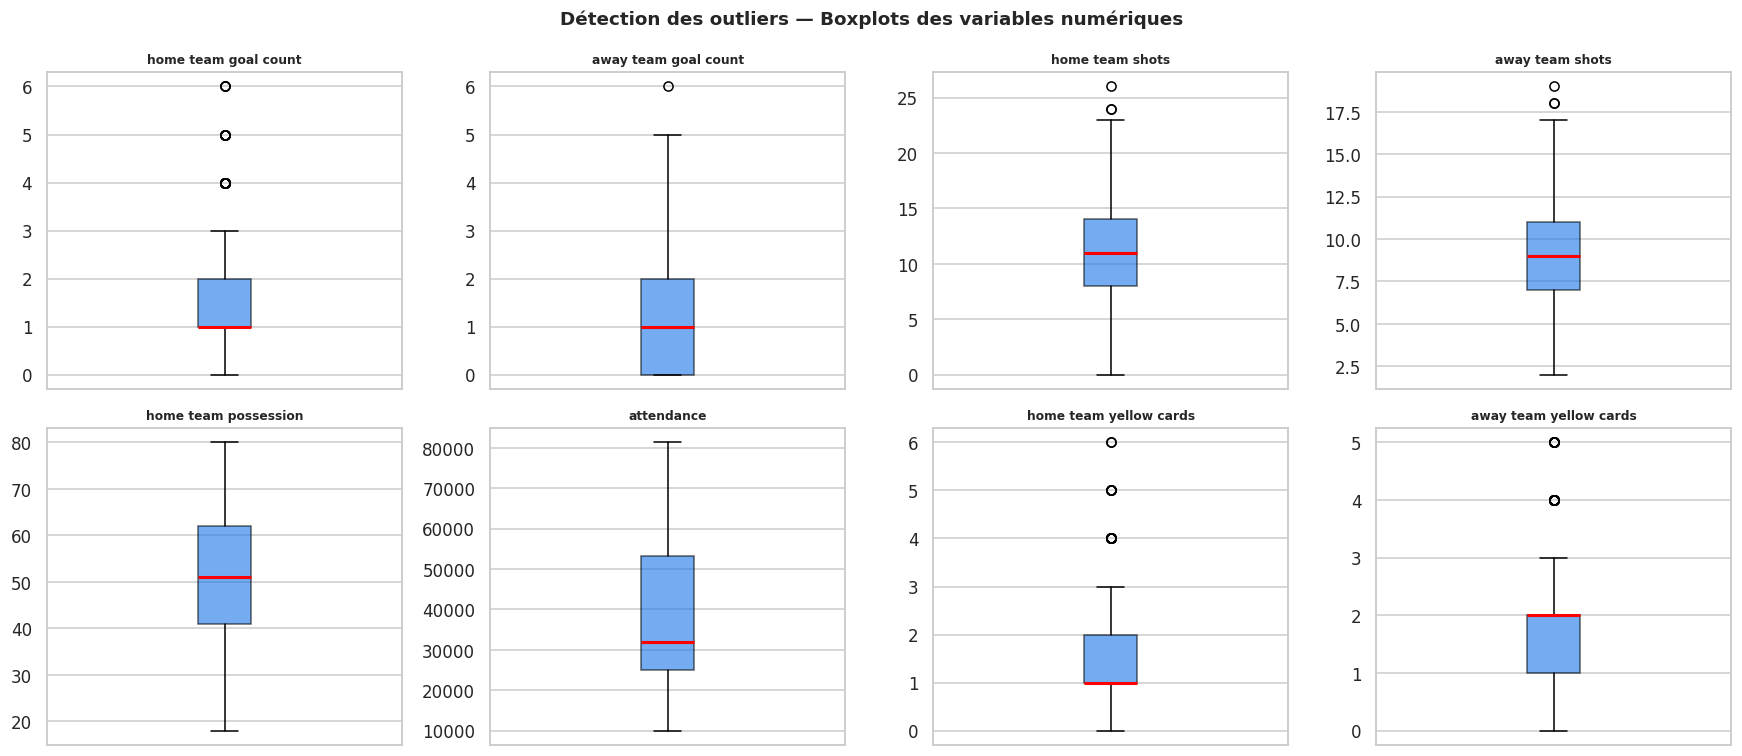

In [ ]:
# Boxplots des variables numériques clés
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, num_cols):
    ax.boxplot(df[col].dropna(), vert=True, patch_artist=True,
               boxprops=dict(facecolor='#1a73e8', alpha=0.6),
               medianprops=dict(color='red', linewidth=2))
    ax.set_title(col.replace('_',' '), fontsize=8, fontweight='bold')
    ax.set_xticks([])

plt.suptitle('Détection des outliers — Boxplots des variables numériques', fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

In [ ]:
# --- Création de variables dérivées ---
df['total_goal_count']     = df['home_team_goal_count'] + df['away_team_goal_count']
df['total_shots']          = df['home_team_shots'] + df['away_team_shots']
df['total_corners']        = df['home_team_corner_count'] + df['away_team_corner_count']
df['total_yellow_cards']   = df['home_team_yellow_cards'] + df['away_team_yellow_cards']
df['total_red_cards']      = df['home_team_red_cards'] + df['away_team_red_cards']
df['total_shots_on_target']= df['home_team_shots_on_target'] + df['away_team_shots_on_target']

# Résultat du match du point de vue domicile
df['result'] = np.where(df['home_team_goal_count'] > df['away_team_goal_count'], 'Victoire domicile',
               np.where(df['home_team_goal_count'] < df['away_team_goal_count'], 'Victoire extérieur', 'Nul'))

# Match à buts multiples
df['high_scoring'] = (df['total_goal_count'] >= 3).astype(int)

print('✅ Variables dérivées créées :')
new_cols = ['total_goal_count','total_shots','total_corners','total_yellow_cards',
            'total_red_cards','total_shots_on_target','result','high_scoring']
print(df[new_cols].head(5))

✅ Variables dérivées créées :
   total_goal_count  total_shots  total_corners  total_yellow_cards  \
0                 3           16              7                   3   
1                 3           24              8                   4   
2                 2           18             11                   2   
3                 2           22             10                   3   
4                 3           14              7                   3   

   total_red_cards  total_shots_on_target              result  high_scoring  
0                0                     12   Victoire domicile             1  
1                0                      9  Victoire extérieur             1  
2                0                      7   Victoire domicile             0  
3                0                     18  Victoire extérieur             0  
4                0                      7  Victoire extérieur             1  


---
<a id='3'></a>
## 3. 📊 Statistique Descriptive Univariée

L'analyse univariée examine **chaque variable indépendamment** à travers ses mesures de tendance centrale (moyenne, médiane, mode), de dispersion (écart-type, variance, IQR) et sa forme de distribution (histogrammes, asymétrie, aplatissement).

In [ ]:
# Table complète des statistiques descriptives
analyse_cols = [
    'home_team_goal_count', 'away_team_goal_count', 'total_goal_count',
    'home_team_shots', 'away_team_shots',
    'home_team_shots_on_target', 'away_team_shots_on_target',
    'home_team_possession',
    'home_team_corner_count', 'away_team_corner_count', 'total_corners',
    'total_yellow_cards', 'total_red_cards',
    'attendance'
]

desc = df[analyse_cols].describe().T
desc['variance']  = df[analyse_cols].var().round(2)
desc['skewness']  = df[analyse_cols].skew().round(3)
desc['kurtosis']  = df[analyse_cols].kurtosis().round(3)
desc['IQR']       = (df[analyse_cols].quantile(0.75) - df[analyse_cols].quantile(0.25)).round(2)
desc = desc[['mean','50%','std','variance','min','max','IQR','skewness','kurtosis']]
desc.columns = ['Moyenne','Médiane','Écart-type','Variance','Min','Max','IQR','Asymétrie','Aplatissement']
desc.round(3)

,Moyenne,Médiane,Écart-type,Variance,Min,Max,IQR,Asymétrie,Aplatissement
home_team_goal_count,1.568,1.0,1.313,1.720000e+00,0.0,6.0,1.00,0.807,0.392
away_team_goal_count,1.253,1.0,1.180,1.390000e+00,0.0,6.0,2.00,0.972,0.930
total_goal_count,2.821,3.0,1.601,2.560000e+00,0.0,8.0,2.00,0.461,0.029
home_team_shots,11.332,11.0,4.278,1.830000e+01,0.0,26.0,6.00,0.454,0.266
away_team_shots,9.197,9.0,3.342,1.117000e+01,2.0,19.0,4.00,0.251,-0.357
home_team_shots_on_target,5.761,6.0,2.716,7.380000e+00,0.0,15.0,3.00,0.482,0.183
away_team_shots_on_target,4.887,5.0,2.373,5.630000e+00,0.0,13.0,3.00,0.312,0.064
home_team_possession,51.147,51.0,13.838,1.915000e+02,18.0,80.0,21.00,-0.091,-0.784
home_team_corner_count,5.726,5.0,3.026,9.150000e+00,0.0,17.0,4.00,0.573,0.176
away_team_corner_count,4.558,4.0,2.731,7.460000e+00,0.0,14.0,3.25,0.574,0.013


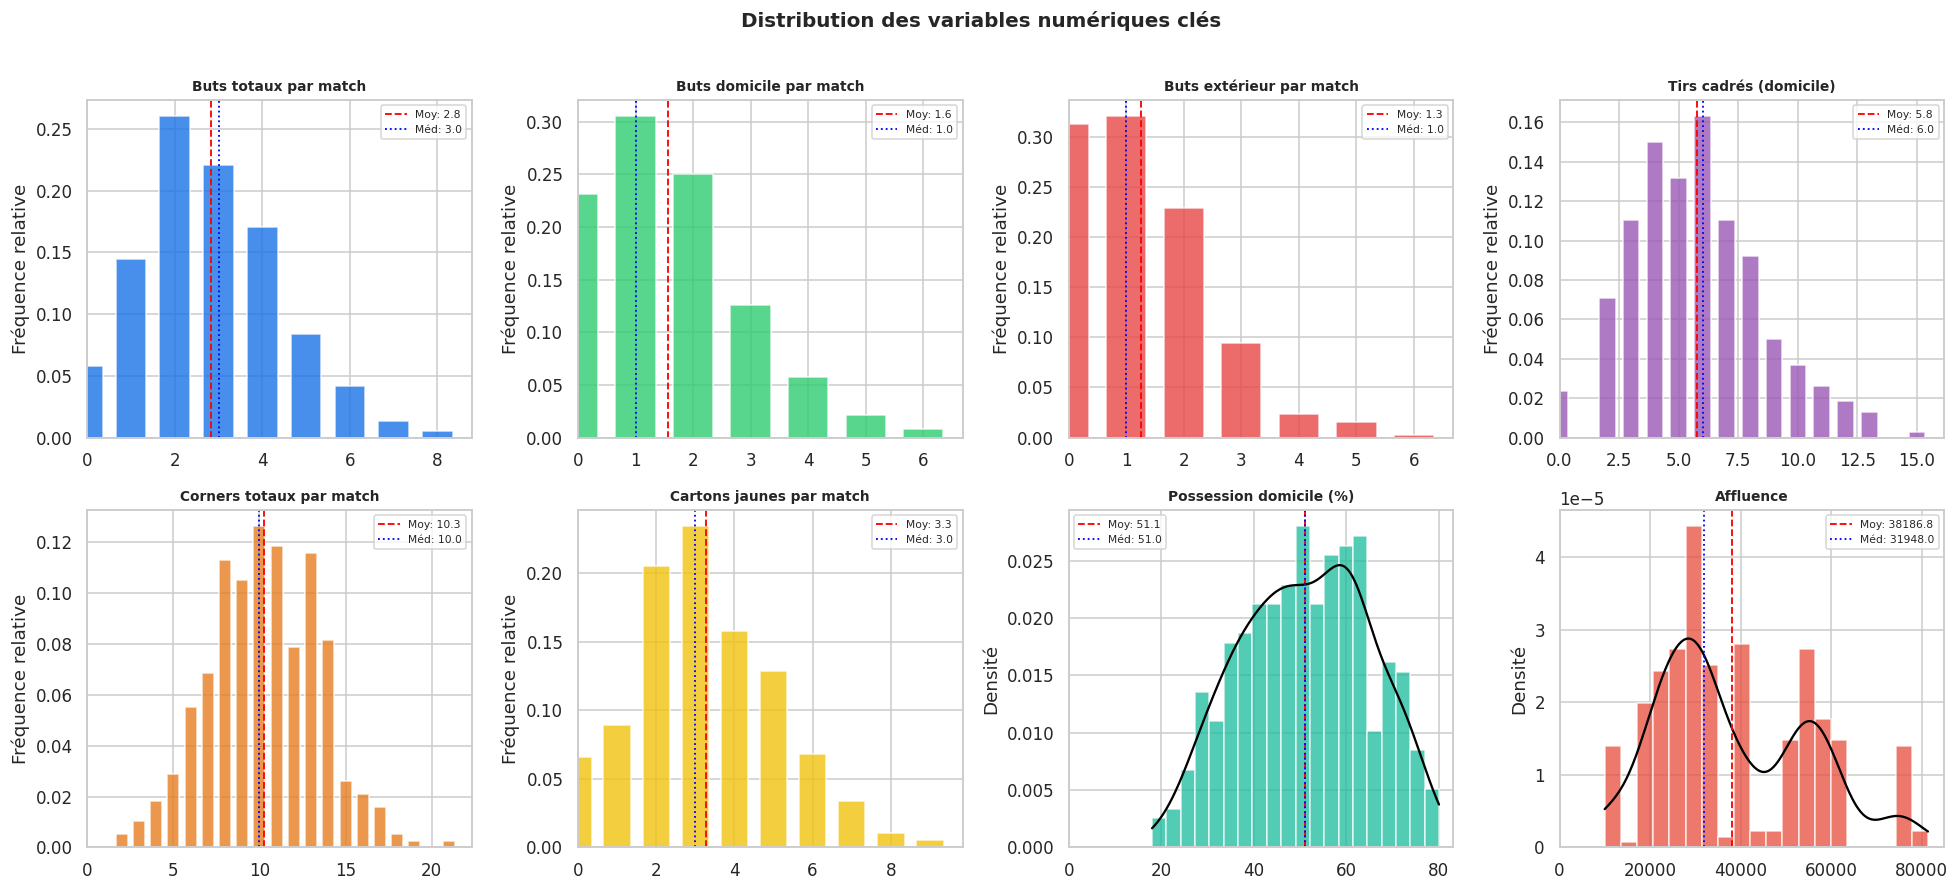

In [ ]:
from scipy.stats import gaussian_kde

# Variables continues (KDE fait sens) vs discrètes (bar chart)
plot_cols = [
    ('total_goal_count',          'Buts totaux par match',       '#1a73e8', 'discrete'),
    ('home_team_goal_count',      'Buts domicile par match',     '#2ecc71', 'discrete'),
    ('away_team_goal_count',      'Buts extérieur par match',    '#e84646', 'discrete'),
    ('home_team_shots_on_target', 'Tirs cadrés (domicile)',      '#9b59b6', 'discrete'),
    ('total_corners',             'Corners totaux par match',    '#e67e22', 'discrete'),
    ('total_yellow_cards',        'Cartons jaunes par match',    '#f1c40f', 'discrete'),
    ('home_team_possession',      'Possession domicile (%)',     '#1abc9c', 'continuous'),
    ('attendance',                'Affluence',                   '#e74c3c', 'continuous'),
]

fig, axes = plt.subplots(2, 4, figsize=(18, 8))

for ax, (col, title, color, var_type) in zip(axes.flat, plot_cols):
    data = df[col].dropna()

    if var_type == 'discrete':
        # Bar chart par valeur exacte — pas d'histogramme continu ni de KDE
        counts = data.value_counts().sort_index()
        probs  = counts / counts.sum()
        ax.bar(probs.index, probs.values, color=color, edgecolor='white',
               alpha=0.80, width=0.7)
        ax.set_ylabel('Fréquence relative')
    else:
        # Histogramme normal + KDE clippé aux bornes réelles
        ax.hist(data, bins=20, color=color, edgecolor='white',
                alpha=0.75, density=True)
        kde = gaussian_kde(data)
        x_min, x_max = data.min(), data.max()
        x_range = np.linspace(x_min, x_max, 300)   # bornes réelles uniquement
        ax.plot(x_range, kde(x_range), color='black', linewidth=1.5)
        ax.set_ylabel('Densité')

    ax.axvline(data.mean(),   color='red',  linestyle='--', linewidth=1.2,
               label=f'Moy: {data.mean():.1f}')
    ax.axvline(data.median(), color='blue', linestyle=':',  linewidth=1.2,
               label=f'Méd: {data.median():.1f}')
    ax.set_title(title, fontweight='bold', fontsize=9)
    ax.set_xlim(left=0)   # jamais de valeurs négatives sur l'axe X
    ax.legend(fontsize=7)

plt.suptitle('Distribution des variables numériques clés',
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# Test de normalité — Shapiro-Wilk
print('=== Test de Shapiro-Wilk (H0 : distribution normale) ===')
print(f'{"Variable":<35} {"Stat W":>10} {"p-value":>12} {"Normal ? (α=0.05)":>20}')
print('-' * 80)
for col in analyse_cols:
    sample = df[col].dropna()
    if len(sample) > 5000:
        sample = sample.sample(5000, random_state=42)
    stat, p = stats.shapiro(sample)
    normal = '✅ Oui' if p > 0.05 else '❌ Non'
    print(f'{col:<35} {stat:>10.4f} {p:>12.4e} {normal:>20}')

=== Test de Shapiro-Wilk (H0 : distribution normale) ===
Variable                                Stat W      p-value    Normal ? (α=0.05)
--------------------------------------------------------------------------------
home_team_goal_count                    0.8925   1.0749e-15                ❌ Non
away_team_goal_count                    0.8600   5.6703e-18                ❌ Non
total_goal_count                        0.9501   4.9103e-10                ❌ Non
home_team_shots                         0.9816   8.9242e-05                ❌ Non
away_team_shots                         0.9842   3.5863e-04                ❌ Non
home_team_shots_on_target               0.9699   4.5787e-07                ❌ Non
away_team_shots_on_target               0.9721   1.1050e-06                ❌ Non
home_team_possession                    0.9848   5.0869e-04                ❌ Non
home_team_corner_count                  0.9656   8.4435e-08                ❌ Non
away_team_corner_count                  0.9603   1.2

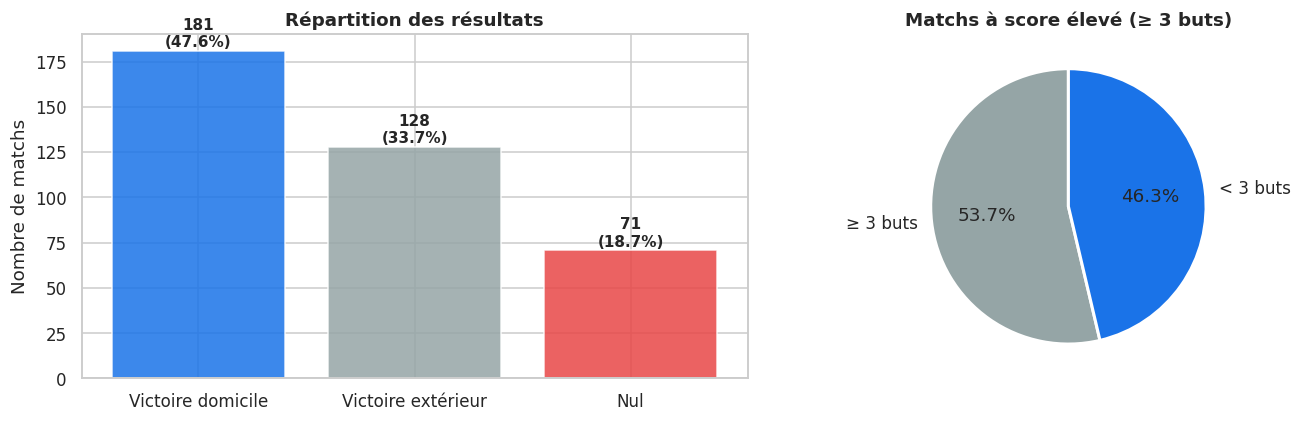

In [ ]:
# Variables catégorielles — Fréquences
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

# Résultat des matchs
result_counts = df['result'].value_counts()
axes[0].bar(result_counts.index, result_counts.values,
            color=['#1a73e8','#95a5a6','#e84646'], edgecolor='white', alpha=0.85)
for i, (idx, val) in enumerate(result_counts.items()):
    axes[0].text(i, val+2, f'{val}\n({val/len(df)*100:.1f}%)', ha='center', fontsize=10, fontweight='bold')
axes[0].set_title('Répartition des résultats', fontweight='bold')
axes[0].set_ylabel('Nombre de matchs')

# Matchs à score élevé
hs = df['high_scoring'].value_counts().rename({0:'< 3 buts', 1:'≥ 3 buts'})
axes[1].pie(hs.values, labels=hs.index, autopct='%1.1f%%',
            colors=['#95a5a6','#1a73e8'], startangle=90,
            wedgeprops={'edgecolor':'white','linewidth':2})
axes[1].set_title('Matchs à score élevé (≥ 3 buts)', fontweight='bold')

plt.tight_layout()
plt.show()

---
<a id='4'></a>
## 4. 🔬 Analyse de la Fiabilité

L'analyse de fiabilité mesure la **cohérence interne** d'un groupe de variables censées mesurer un même concept latent.  
Nous utilisons le **coefficient Alpha de Cronbach**, standard en sciences sociales et data mining.

| Valeur α | Interprétation |
|----------|----------------|
| α ≥ 0.9  | Excellente |
| 0.8 ≤ α < 0.9 | Bonne |
| 0.7 ≤ α < 0.8 | Acceptable |
| 0.6 ≤ α < 0.7 | Questionnable |
| α < 0.6  | Faible / Inacceptable |

Nous testons la fiabilité de **3 dimensions conceptuelles** :
- **Dimension Offensive** : buts, tirs, tirs cadrés
- **Dimension Pression** : corners, possession
- **Dimension Intensité** : cartons jaunes, fautes

In [ ]:
def cronbach_alpha(df_items):
    """Calcule le coefficient Alpha de Cronbach pour un ensemble d'items."""
    df_items = df_items.dropna()
    n = df_items.shape[1]
    var_items = df_items.var(axis=0, ddof=1).sum()
    var_total = df_items.sum(axis=1).var(ddof=1)
    alpha = (n / (n - 1)) * (1 - var_items / var_total)
    return round(alpha, 4)

print('Fonction Alpha de Cronbach définie ✅')

Fonction Alpha de Cronbach définie ✅


In [ ]:
dimensions = {
    'Offensive (buts + tirs)': [
        'home_team_goal_count', 'home_team_shots',
        'home_team_shots_on_target', 'home_team_shots_off_target'
    ],
    'Pression (corners + possession)': [
        'home_team_corner_count', 'away_team_corner_count',
        'home_team_possession'
    ],
    'Intensité (cartons + fautes)': [
        'home_team_yellow_cards', 'away_team_yellow_cards',
        'home_team_fouls', 'away_team_fouls'
    ]
}



def interpret(a):
    if a >= 0.9: return 'Excellente'
    elif a >= 0.8: return 'Bonne'
    elif a >= 0.7: return 'Acceptable'
    elif a >= 0.6: return 'Questionnable'
    else: return 'Faible'

print(f'{"Dimension":<40} {"Alpha":>8} {"Interprétation":>18}')
print('-' * 70)
results_alpha = {}
for dim, cols in dimensions.items():
    alpha = cronbach_alpha(df[cols])
    results_alpha[dim] = alpha
    print(f'{dim:<40} {alpha:>8.4f} {interpret(alpha):>18}')

Dimension                                   Alpha     Interprétation
----------------------------------------------------------------------
Offensive (buts + tirs)                    0.7707         Acceptable
Pression (corners + possession)           -0.0075             Faible
Intensité (cartons + fautes)               0.3737             Faible


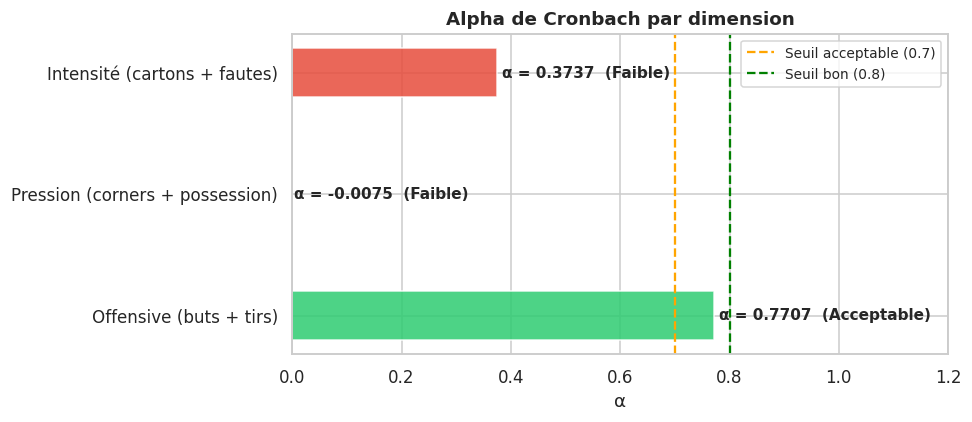

In [ ]:
fig, ax = plt.subplots(figsize=(9, 4))
dims = list(results_alpha.keys())
alphas = list(results_alpha.values())
colors_a = ['#2ecc71' if a >= 0.7 else '#e67e22' if a >= 0.6 else '#e74c3c' for a in alphas]

bars = ax.barh(dims, alphas, color=colors_a, edgecolor='white', alpha=0.85, height=0.4)
for bar, val in zip(bars, alphas):
    ax.text(val + 0.01, bar.get_y() + bar.get_height()/2,
            f'α = {val:.4f}  ({interpret(val)})', va='center', fontsize=10, fontweight='bold')
ax.axvline(0.7, color='orange', linestyle='--', linewidth=1.5, label='Seuil acceptable (0.7)')
ax.axvline(0.8, color='green',  linestyle='--', linewidth=1.5, label='Seuil bon (0.8)')
ax.set_xlim(0, 1.2)
ax.set_title('Alpha de Cronbach par dimension', fontweight='bold', fontsize=12)
ax.set_xlabel('α')
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

In [ ]:
dim_cols = dimensions['Offensive (buts + tirs)']
total_score = df[dim_cols].sum(axis=1)

print('=== Corrélation item-total — Dimension Offensive ===')
print(f'{"Item":<35} {"r item-total":>15} {"α si supprimé":>15}')
print('-' * 68)
for col in dim_cols:
    r = df[col].corr(total_score - df[col])
    remaining = [c for c in dim_cols if c != col]
    alpha_if_removed = cronbach_alpha(df[remaining])
    print(f'{col:<35} {r:>15.4f} {alpha_if_removed:>15.4f}')

=== Corrélation item-total — Dimension Offensive ===
Item                                   r item-total   α si supprimé
--------------------------------------------------------------------
home_team_goal_count                         0.3976          0.8102
home_team_shots                              0.9699          0.4536
home_team_shots_on_target                    0.6370          0.6861
home_team_shots_off_target                   0.5328          0.7359


---
<a id='5'></a>
## 5. 📈 Statistique Descriptive Bivariée

L'analyse bivariée étudie les **relations entre deux variables à la fois**. Selon leurs types, différentes méthodes sont utilisées :

| Paire de variables | Méthode |
|--------------------|----------|
| Numérique × Numérique | Corrélation de Pearson, Scatter plot |
| Catégorielle × Numérique | ANOVA / Box plot |
| Catégorielle × Catégorielle | Chi-², tableau de contingence |

In [ ]:
# --- Corrélations de Pearson (Num × Num) ---
pearson_pairs = [
    ('home_team_shots_on_target', 'home_team_goal_count',  'Tirs cadrés vs Buts (domicile)'),
    ('home_team_possession',      'home_team_goal_count',  'Possession vs Buts (domicile)'),
    ('total_corners',             'total_goal_count',      'Corners vs Buts totaux'),
    ('total_yellow_cards',        'total_goal_count',      'Cartons jaunes vs Buts totaux'),
    ('attendance',                'total_goal_count',      'Affluence vs Buts totaux'),
    ('home_team_fouls',           'home_team_yellow_cards','Fautes vs Cartons (domicile)'),
]

print(f'{"Paire":<45} {"r Pearson":>12} {"p-value":>12} {"Sig. (α=0.05)":>15}')
print('-' * 87)
for x_col, y_col, label in pearson_pairs:
    r, p = stats.pearsonr(df[x_col].dropna(), df[y_col].dropna())
    sig = '✅' if p < 0.05 else '❌'
    print(f'{label:<45} {r:>12.4f} {p:>12.4e} {sig:>15}')

Paire                                            r Pearson      p-value   Sig. (α=0.05)
---------------------------------------------------------------------------------------
Tirs cadrés vs Buts (domicile)                      0.5933   1.6657e-37               ✅
Possession vs Buts (domicile)                       0.2357   3.3870e-06               ✅
Corners vs Buts totaux                             -0.1072   3.6639e-02               ✅
Cartons jaunes vs Buts totaux                       0.0060   9.0698e-01               ❌
Affluence vs Buts totaux                            0.0864   9.2436e-02               ❌
Fautes vs Cartons (domicile)                        0.3479   2.9606e-12               ✅


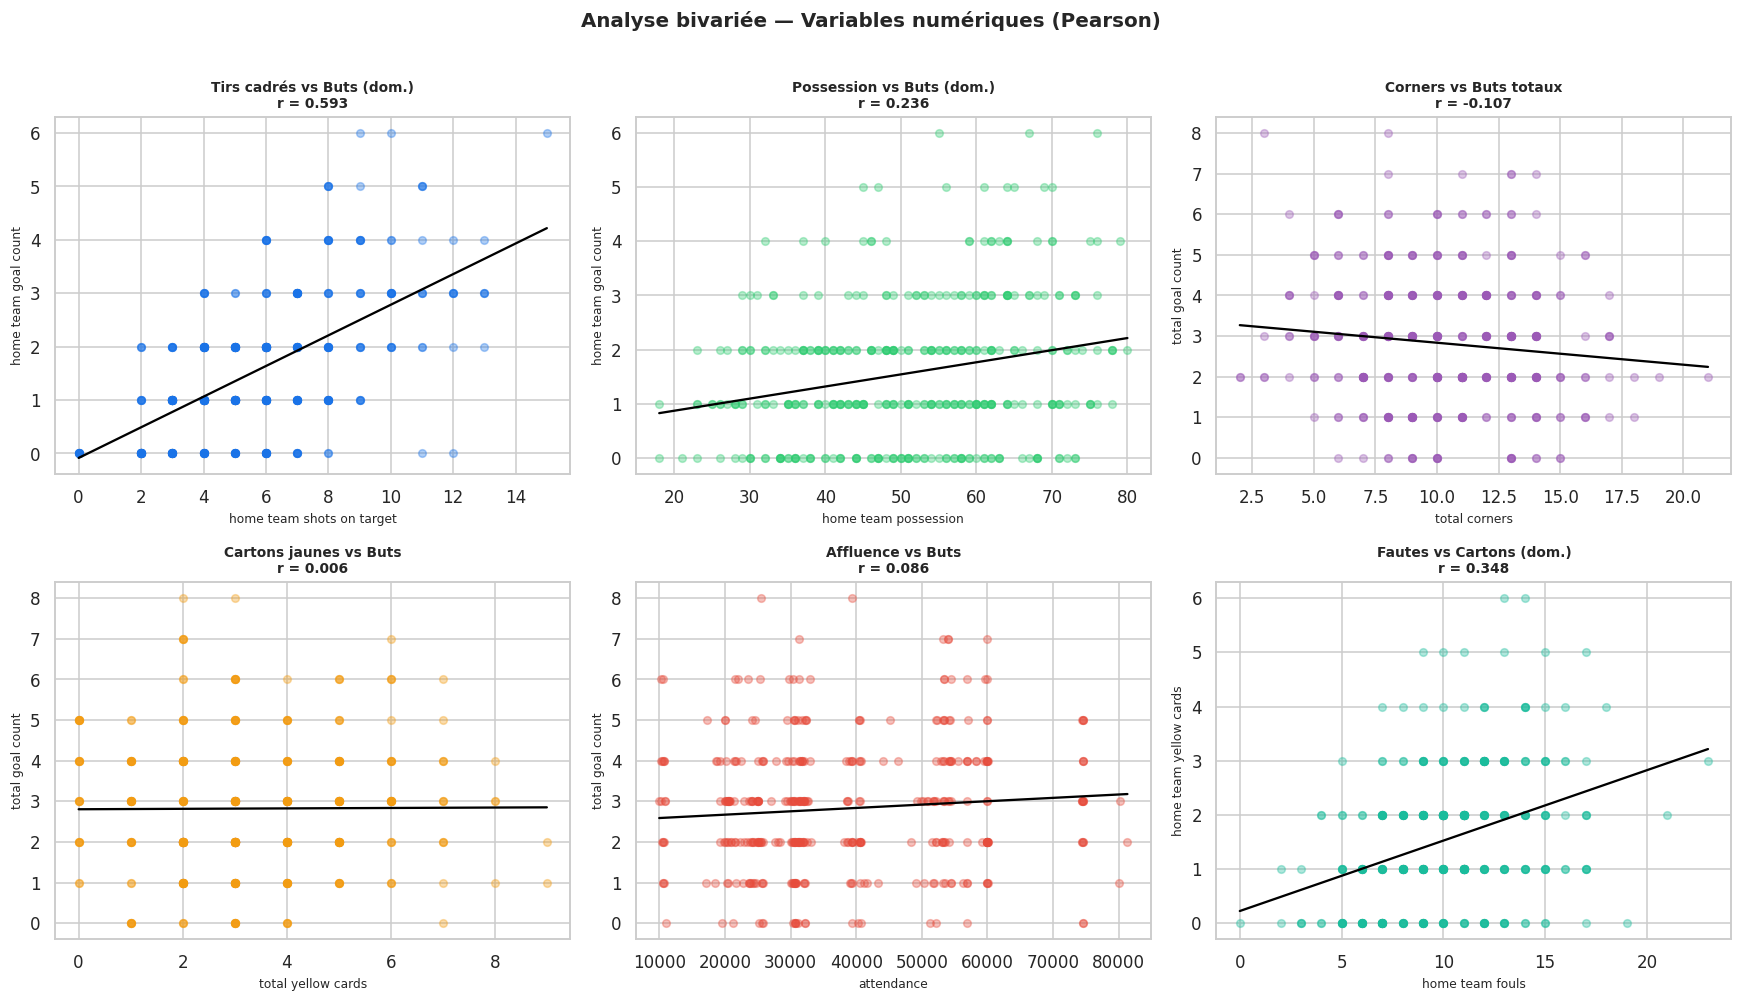

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))

scatter_config = [
    ('home_team_shots_on_target', 'home_team_goal_count',  'Tirs cadrés vs Buts (dom.)',   '#1a73e8'),
    ('home_team_possession',      'home_team_goal_count',  'Possession vs Buts (dom.)',     '#2ecc71'),
    ('total_corners',             'total_goal_count',      'Corners vs Buts totaux',        '#9b59b6'),
    ('total_yellow_cards',        'total_goal_count',      'Cartons jaunes vs Buts',        '#f39c12'),
    ('attendance',                'total_goal_count',      'Affluence vs Buts',             '#e74c3c'),
    ('home_team_fouls',           'home_team_yellow_cards','Fautes vs Cartons (dom.)',      '#1abc9c'),
]

for ax, (x, y, title, color) in zip(axes.flat, scatter_config):
    ax.scatter(df[x], df[y], alpha=0.35, color=color, s=25)
    m, b = np.polyfit(df[x].dropna(), df[y].dropna(), 1)
    xline = np.linspace(df[x].min(), df[x].max(), 100)
    ax.plot(xline, m*xline+b, color='black', linewidth=1.5)
    r, _ = stats.pearsonr(df[x], df[y])
    ax.set_title(f'{title}\nr = {r:.3f}', fontweight='bold', fontsize=9)
    ax.set_xlabel(x.replace('_',' '), fontsize=8)
    ax.set_ylabel(y.replace('_',' '), fontsize=8)

plt.suptitle('Analyse bivariée — Variables numériques (Pearson)', fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# --- ANOVA : Résultat (catégorielle) vs Variables numériques ---
anova_vars = [
    'home_team_goal_count', 'home_team_shots_on_target',
    'home_team_possession', 'attendance'
]

print('=== ANOVA — Résultat du match vs Variables numériques ===')
print(f'{"Variable":<35} {"F-stat":>10} {"p-value":>12} {"Sig. (α=0.05)":>15}')
print('-' * 75)
for var in anova_vars:
    groups = [df[df['result']==r][var].dropna() for r in df['result'].unique()]
    F, p = f_oneway(*groups)
    sig = '✅' if p < 0.05 else '❌'
    print(f'{var:<35} {F:>10.3f} {p:>12.4e} {sig:>15}')

=== ANOVA — Résultat du match vs Variables numériques ===
Variable                                F-stat      p-value   Sig. (α=0.05)
---------------------------------------------------------------------------
home_team_goal_count                   194.261   1.0334e-58               ✅
home_team_shots_on_target               39.244   3.2912e-16               ✅
home_team_possession                    11.983   9.0071e-06               ✅
attendance                              10.910   2.4766e-05               ✅


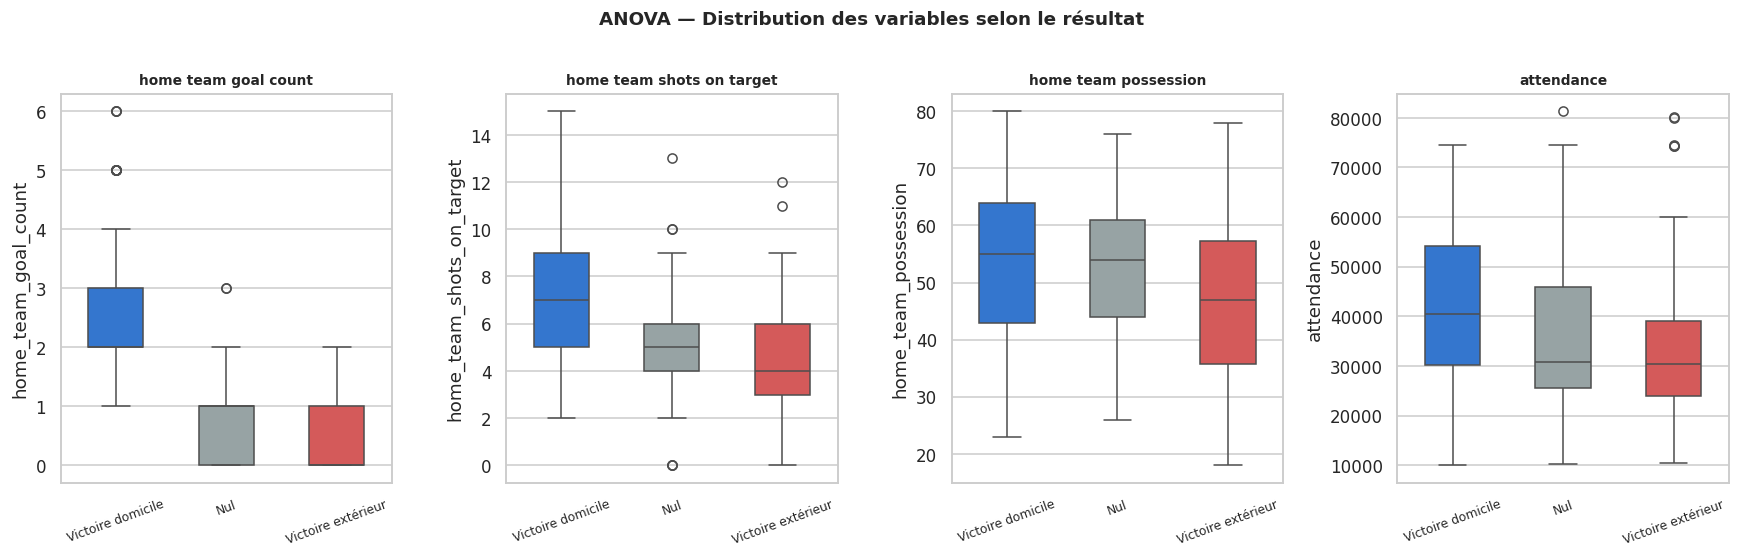

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 5))
order = ['Victoire domicile', 'Nul', 'Victoire extérieur']
palette = {'Victoire domicile':'#1a73e8', 'Nul':'#95a5a6', 'Victoire extérieur':'#e84646'}

for ax, var in zip(axes, anova_vars):
    sns.boxplot(data=df, x='result', y=var, order=order, palette=palette, ax=ax, width=0.5)
    ax.set_title(var.replace('_',' '), fontweight='bold', fontsize=9)
    ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=20, labelsize=8)

plt.suptitle('ANOVA — Distribution des variables selon le résultat', fontsize=12, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

In [ ]:
# --- Test du Chi-² : Résultat vs Match à score élevé ---
contingency = pd.crosstab(df['result'], df['high_scoring'],
                          rownames=['Résultat'], colnames=['Score élevé (≥3 buts)'])
contingency.columns = ['< 3 buts','≥ 3 buts']

print('=== Tableau de contingence ===')
print(contingency)

chi2, p, dof, expected = chi2_contingency(contingency)
print(f'\nChi² = {chi2:.4f}')
print(f'p-value = {p:.4e}')
print(f'Degrés de liberté = {dof}')
print(f'\nConclusion : {"✅ Association significative (p < 0.05)" if p < 0.05 else "❌ Pas d\'association significative"}')

=== Tableau de contingence ===
                    < 3 buts  ≥ 3 buts
Résultat                              
Nul                       54        17
Victoire domicile         73       108
Victoire extérieur        49        79

Chi² = 31.1871
p-value = 1.6897e-07
Degrés de liberté = 2

Conclusion : ✅ Association significative (p < 0.05)


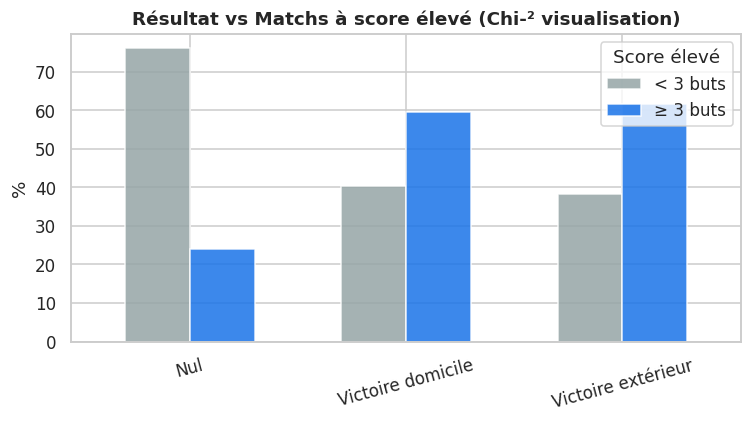

In [ ]:
fig, ax = plt.subplots(figsize=(7, 4))
contingency_pct = contingency.div(contingency.sum(axis=1), axis=0) * 100
contingency_pct.plot(kind='bar', ax=ax, color=['#95a5a6','#1a73e8'],
                     edgecolor='white', alpha=0.85, width=0.6)
ax.set_title('Résultat vs Matchs à score élevé (Chi-² visualisation)', fontweight='bold')
ax.set_ylabel('%')
ax.set_xlabel('')
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Score élevé')
plt.tight_layout()
plt.show()

---
<a id='6'></a>
## 6. 📐 Statistique Descriptive Multivariée

L'analyse multivariée examine **plusieurs variables simultanément** pour détecter des structures, des patterns et des relations complexes. Nous appliquons :

- **Matrice de corrélation complète** (heatmap)
- **Scatter matrix (Pairplot)** — relations croisées entre variables clés
- **Analyse en Composantes Principales (ACP / PCA)** — réduction de dimensionnalité
- **Profil des équipes** — comparaison multivariée par équipe

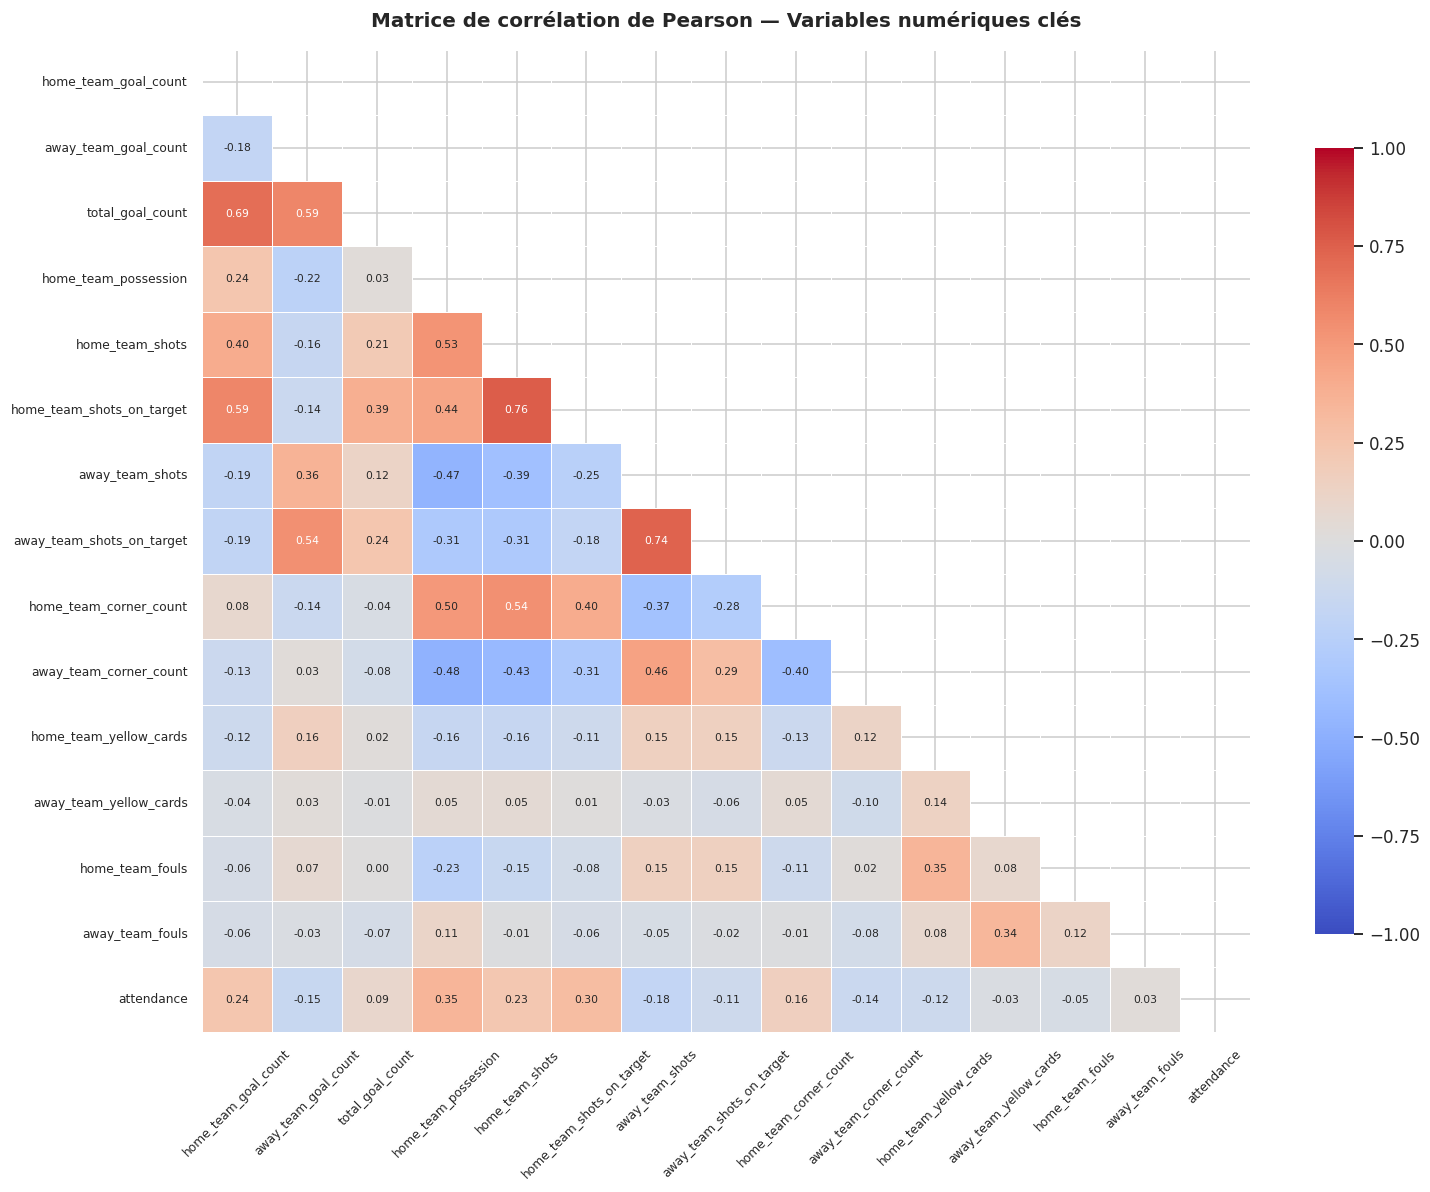

In [ ]:
# --- Matrice de corrélation complète ---
corr_cols = [
    'home_team_goal_count','away_team_goal_count','total_goal_count',
    'home_team_possession','home_team_shots','home_team_shots_on_target',
    'away_team_shots','away_team_shots_on_target',
    'home_team_corner_count','away_team_corner_count',
    'home_team_yellow_cards','away_team_yellow_cards',
    'home_team_fouls','away_team_fouls','attendance'
]

corr_matrix = df[corr_cols].corr().round(2)

fig, ax = plt.subplots(figsize=(14, 11))
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))
sns.heatmap(
    corr_matrix, ax=ax, annot=True, fmt='.2f',
    cmap='coolwarm', linewidths=0.4, mask=mask,
    vmin=-1, vmax=1, annot_kws={'size': 7},
    cbar_kws={'shrink': 0.8}
)
ax.set_title('Matrice de corrélation de Pearson — Variables numériques clés',
             fontweight='bold', fontsize=13, pad=15)
ax.tick_params(axis='x', rotation=45, labelsize=8)
ax.tick_params(axis='y', rotation=0,  labelsize=8)
plt.tight_layout()
plt.show()

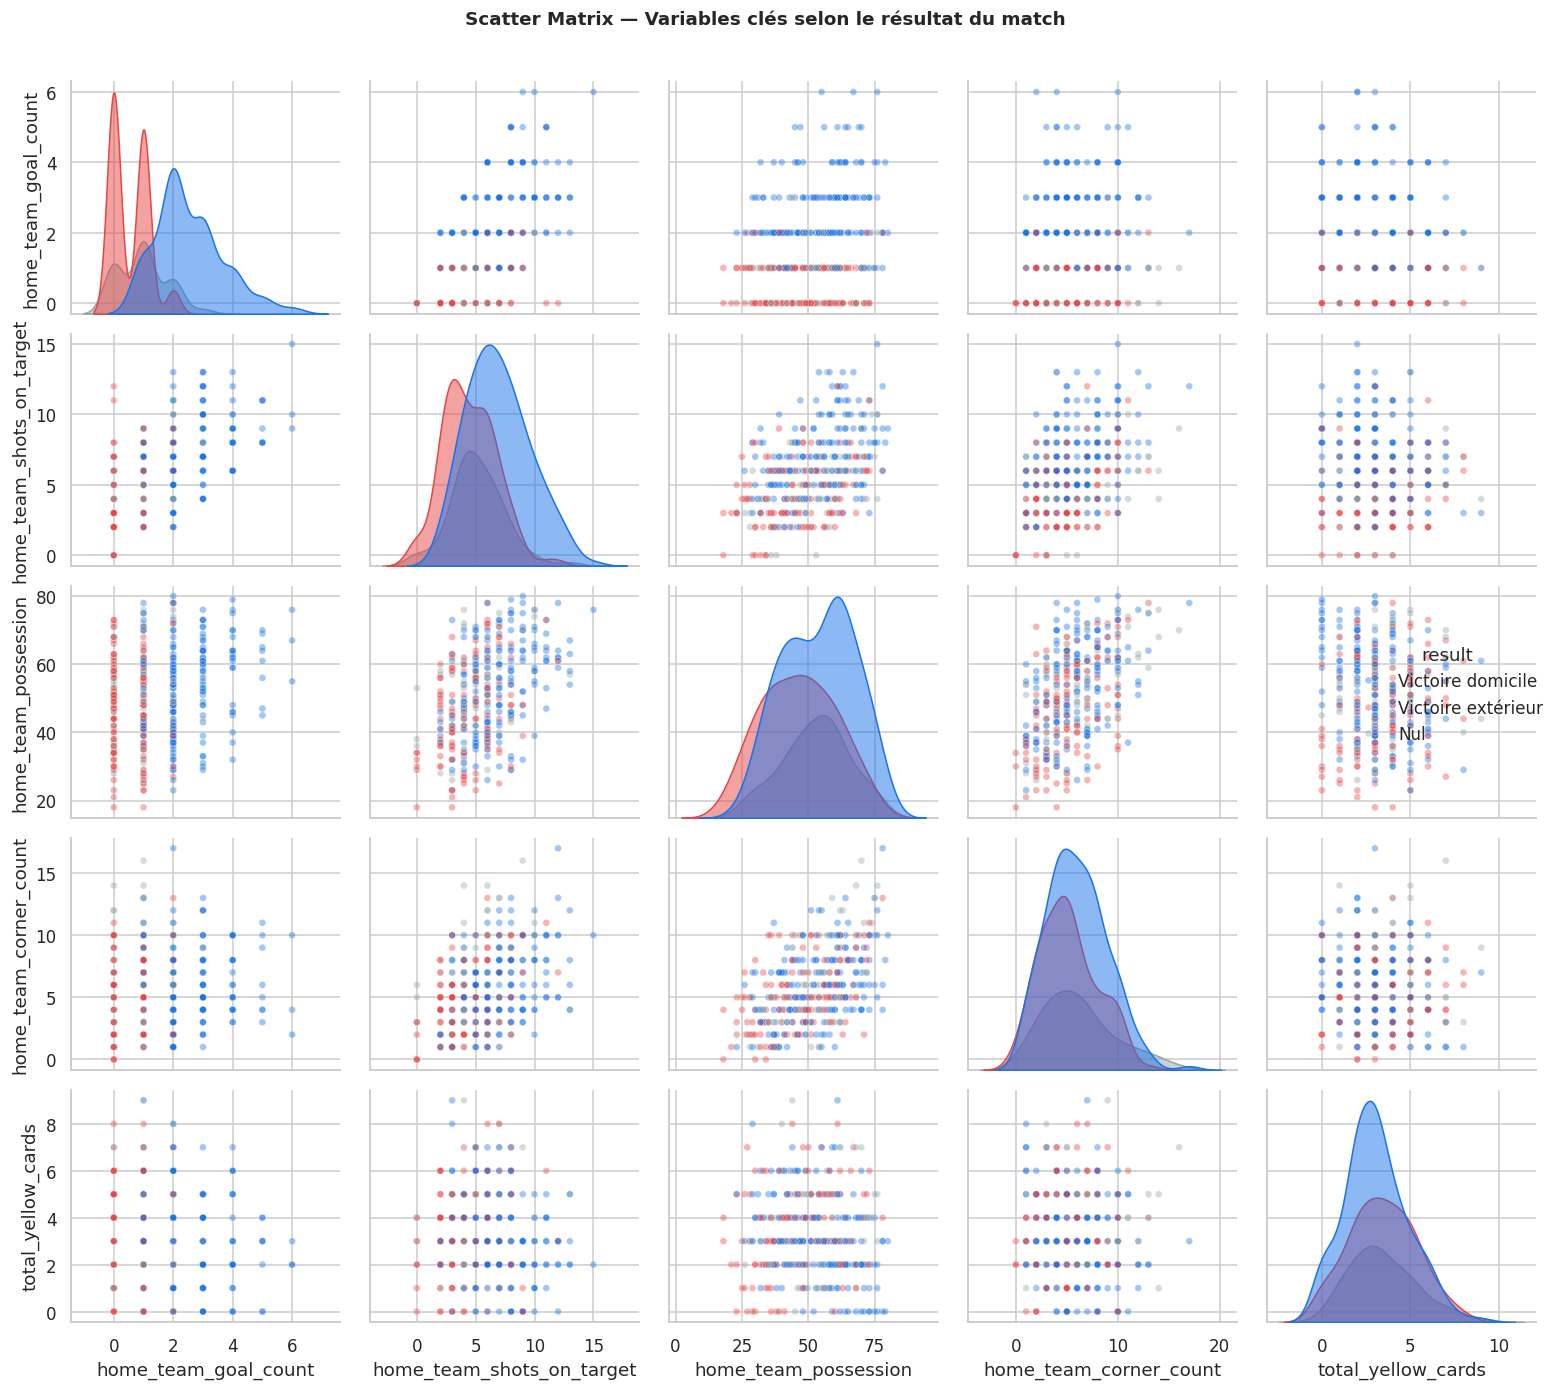

In [ ]:
# --- Scatter Matrix (Pairplot) ---
pairplot_cols = [
    'home_team_goal_count', 'home_team_shots_on_target',
    'home_team_possession', 'home_team_corner_count', 'total_yellow_cards'
]

pair_df = df[pairplot_cols + ['result']].copy()
palette_pair = {'Victoire domicile':'#1a73e8', 'Nul':'#95a5a6', 'Victoire extérieur':'#e84646'}

g = sns.pairplot(
    pair_df, hue='result', palette=palette_pair,
    diag_kind='kde', plot_kws={'alpha':0.4, 's':20},
    diag_kws={'fill':True, 'alpha':0.5}
)
g.figure.suptitle('Scatter Matrix — Variables clés selon le résultat du match',
                   y=1.01, fontweight='bold', fontsize=12)
plt.tight_layout()
plt.show()

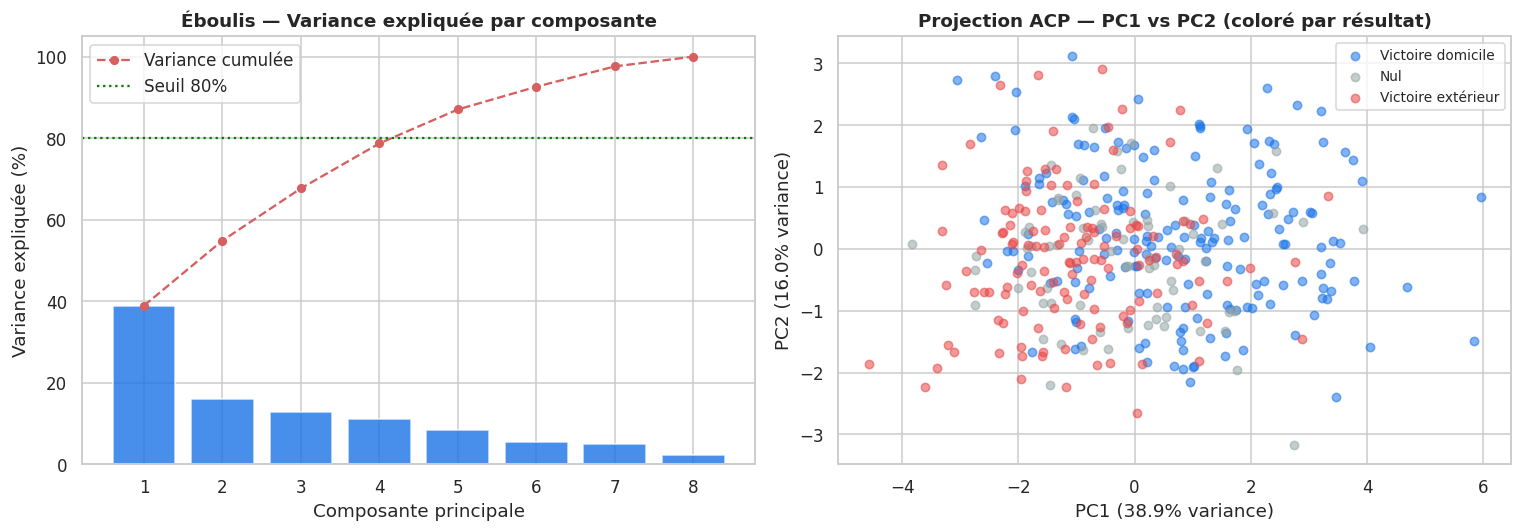

Variance expliquée par PC1 + PC2 : 54.9%
Composantes pour 80% de variance  : 5


In [ ]:
# --- ACP (PCA) ---
pca_cols = [
    'home_team_goal_count', 'home_team_shots', 'home_team_shots_on_target',
    'home_team_possession', 'home_team_corner_count',
    'home_team_yellow_cards', 'home_team_fouls', 'attendance'
]

X = df[pca_cols].dropna()
idx = X.index

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

pca = PCA()
pca.fit(X_scaled)

explained = pca.explained_variance_ratio_ * 100
cumul = np.cumsum(explained)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Éboulis (Scree plot)
axes[0].bar(range(1, len(explained)+1), explained, color='#1a73e8', alpha=0.8, edgecolor='white')
axes[0].plot(range(1, len(explained)+1), cumul, 'ro--', linewidth=1.5, markersize=5, label='Variance cumulée')
axes[0].axhline(80, color='green', linestyle=':', label='Seuil 80%')
axes[0].set_title('Éboulis — Variance expliquée par composante', fontweight='bold')
axes[0].set_xlabel('Composante principale')
axes[0].set_ylabel('Variance expliquée (%)')
axes[0].legend()

# Projection PC1 vs PC2
X_pca = pca.transform(X_scaled)
results_pca = df.loc[idx, 'result']
color_map = {'Victoire domicile':'#1a73e8', 'Nul':'#95a5a6', 'Victoire extérieur':'#e84646'}
for label, color in color_map.items():
    mask_r = results_pca == label
    axes[1].scatter(X_pca[mask_r, 0], X_pca[mask_r, 1],
                    c=color, label=label, alpha=0.55, s=30)
axes[1].set_xlabel(f'PC1 ({explained[0]:.1f}% variance)')
axes[1].set_ylabel(f'PC2 ({explained[1]:.1f}% variance)')
axes[1].set_title('Projection ACP — PC1 vs PC2 (coloré par résultat)', fontweight='bold')
axes[1].legend(fontsize=9)

plt.tight_layout()
plt.show()

print(f'Variance expliquée par PC1 + PC2 : {cumul[1]:.1f}%')
print(f'Composantes pour 80% de variance  : {np.argmax(cumul >= 80) + 1}')

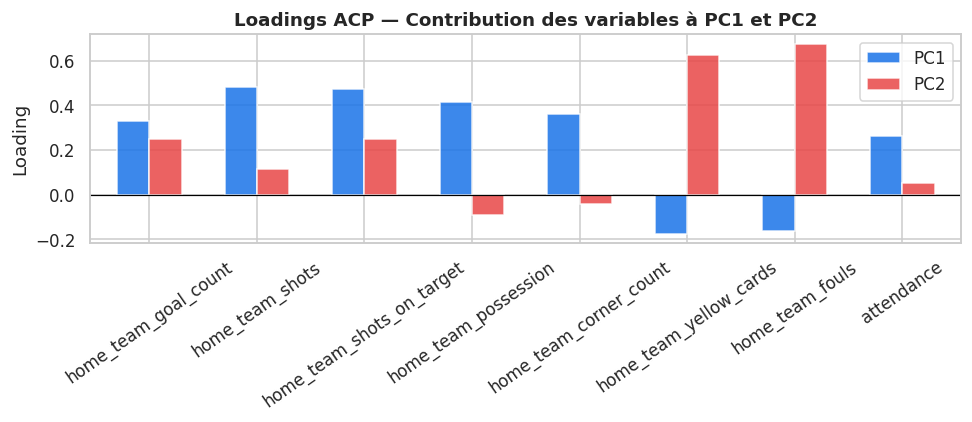


Table des loadings :
                             PC1    PC2    PC3
home_team_goal_count       0.330  0.249  0.613
home_team_shots            0.482  0.116 -0.129
home_team_shots_on_target  0.475  0.250  0.154
home_team_possession       0.417 -0.090 -0.288
home_team_corner_count     0.363 -0.041 -0.602
home_team_yellow_cards    -0.176  0.625 -0.269
home_team_fouls           -0.161  0.677 -0.106
attendance                 0.265  0.054  0.232


In [ ]:
# Contribution des variables aux composantes
loadings = pd.DataFrame(
    pca.components_[:3].T,
    index=pca_cols,
    columns=['PC1','PC2','PC3']
).round(3)

fig, ax = plt.subplots(figsize=(9, 4))
loadings[['PC1','PC2']].plot(kind='bar', ax=ax, color=['#1a73e8','#e84646'],
                              edgecolor='white', alpha=0.85, width=0.6)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_title('Loadings ACP — Contribution des variables à PC1 et PC2', fontweight='bold')
ax.set_ylabel('Loading')
ax.tick_params(axis='x', rotation=35)
ax.legend()
plt.tight_layout()
plt.show()

print('\nTable des loadings :')
print(loadings.to_string())

In [ ]:
# --- Profil Multivarié des Équipes ---
home_agg = df.groupby('home_team_name').agg(
    buts_marques=('home_team_goal_count','mean'),
    tirs_cadres=('home_team_shots_on_target','mean'),
    possession=('home_team_possession','mean'),
    corners=('home_team_corner_count','mean'),
    cartons=('home_team_yellow_cards','mean')
).round(2)

# Normalisation pour le radar
home_norm = (home_agg - home_agg.min()) / (home_agg.max() - home_agg.min())

print('Profil moyen des équipes (matchs à domicile) :')
print(home_agg.sort_values('buts_marques', ascending=False))

Profil moyen des équipes (matchs à domicile) :
                         buts_marques  tirs_cadres  possession  corners  \
home_team_name                                                            
Manchester City                  3.00         8.79       68.37     8.11   
Liverpool                        2.89         7.63       63.79     7.00   
Arsenal                          2.21         6.11       60.89     6.58   
Chelsea                          2.05         7.21       63.89     6.32   
Tottenham Hotspur                1.79         6.53       61.21     5.37   
Manchester United                1.74         7.63       56.21     6.11   
West Ham United                  1.68         5.63       48.95     5.68   
AFC Bournemouth                  1.58         5.26       46.00     5.05   
Everton                          1.58         5.47       53.63     6.26   
Wolverhampton Wanderers          1.47         5.53       46.37     5.74   
Southampton                      1.42         5.68   

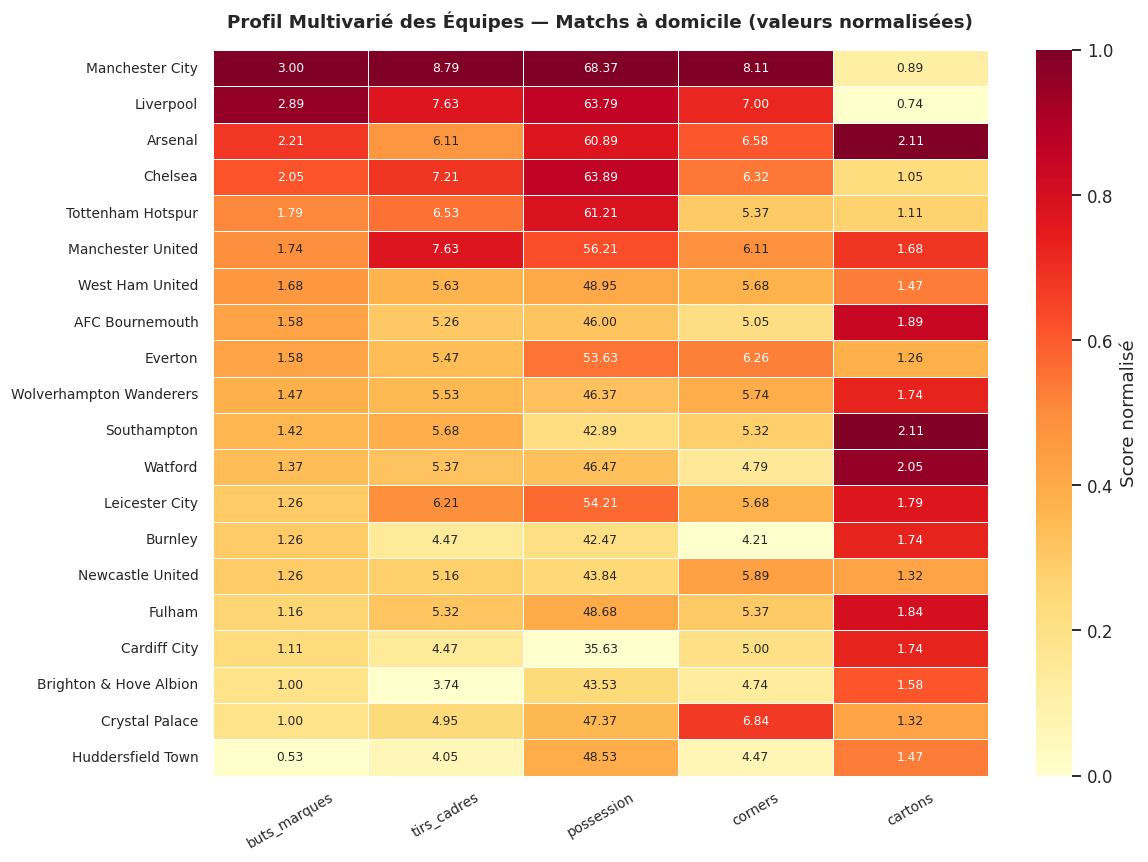

In [ ]:
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(
    home_norm.sort_values('buts_marques', ascending=False),
    annot=home_agg.sort_values('buts_marques', ascending=False),
    fmt='.2f', cmap='YlOrRd', linewidths=0.5,
    annot_kws={'size':8}, ax=ax,
    cbar_kws={'label':'Score normalisé'}
)
ax.set_title('Profil Multivarié des Équipes — Matchs à domicile (valeurs normalisées)',
             fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', rotation=30, labelsize=9)
ax.tick_params(axis='y', rotation=0,  labelsize=9)
plt.tight_layout()
plt.show()

---
<a id='7'></a>
## 7. 📦 Règles d'Association

L'analyse par règles d'association permet de découvrir des **relations fréquentes et significatives entre des événements de match**. Contrairement aux analyses bivariée et multivariée qui examinent des relations linéaires, les règles d'association capturent des **combinaisons multi-variables** et quantifient leur force relative.

Une règle prend la forme **A → B** et est évaluée par trois métriques :
- **Support** : fréquence d'apparition de la combinaison dans l'ensemble des matchs
- **Confiance** : probabilité que B soit vrai sachant que A est vrai
- **Lift** : force de l'association par rapport au hasard (lift > 1 = association réelle)

L'algorithme utilisé est **Apriori**, implémenté via `mlxtend`.

In [ ]:
from mlxtend.frequent_patterns import apriori, association_rules
from mlxtend.preprocessing import TransactionEncoder

### 7.1 Discrétisation des variables

L'algorithme Apriori requiert des données **binaires (0/1)**. Les variables numériques sont donc converties en items binaires à partir de seuils définis sur la base des distributions observées en section 3.

> Exemple : `home_team_possession > 55%` → `home_dominates_poss = True`

In [ ]:
# --- Discretization : Numerical → Binary ---

basket = pd.DataFrame()

# Goals
basket['home_high_scoring']     = (df['home_team_goal_count'] >= 2).astype(int)
basket['away_scored']           = (df['away_team_goal_count'] >= 1).astype(int)
basket['high_scoring_match']    = (df['total_goal_count'] >= 3).astype(int)

# Shots & Possession
basket['home_accurate']         = (df['home_team_shots_on_target'] >= 6).astype(int)
basket['home_dominates_poss']   = (df['home_team_possession'] > 55).astype(int)

# Cards & Corners
basket['aggressive_match']      = (df['total_yellow_cards'] >= 4).astype(int)
basket['many_corners']          = (df['total_corners'] >= 11).astype(int)
basket['home_red_card']         = (df['home_team_red_cards'] >= 1).astype(int)

# Attendance
basket['big_crowd']             = (df['attendance'] > 50000).astype(int)

# Result
basket['home_win']              = (df['result'] == 'Victoire domicile').astype(int)
basket['away_win']              = (df['result'] == 'Victoire extérieur').astype(int)
basket['draw']                  = (df['result'] == 'Nul').astype(int)

print("=== Basket shape:", basket.shape)
print("\n=== Fréquence de chaque item (% des matchs) ===")
freq = (basket.sum() / len(basket) * 100).round(1).sort_values(ascending=False)
print(freq.to_string())

=== Basket shape: (380, 12)

=== Fréquence de chaque item (% des matchs) ===
away_scored            68.7
high_scoring_match     53.7
home_accurate          51.3
home_win               47.6
many_corners           46.8
home_high_scoring      46.3
home_dominates_poss    41.6
aggressive_match       40.5
away_win               33.7
big_crowd              31.8
draw                   18.7
home_red_card           4.7


### 7.2 Vérification des fréquences et nettoyage

Avant d'exécuter Apriori, on vérifie que chaque item couvre une proportion raisonnable de matchs **(entre 15 % et 70 %)**. Un item trop rare (< 10 %) générera des règles non fiables ; un item trop fréquent (> 90 %) n'apportera aucune information discriminante.

> ⚠️ `home_red_card` est supprimé : fréquence = **4.7 %** (18 matchs seulement) — insuffisant pour des règles robustes.

In [ ]:
# Drop too-rare item
basket = basket.drop(columns=['home_red_card'])

# Convert to bool (required by mlxtend)
basket_bool = basket.astype(bool)

print("✅ Basket ready")
print(f"Shape: {basket_bool.shape}")
print(f"\nDtypes check:\n{basket_bool.dtypes.value_counts()}")

✅ Basket ready
Shape: (380, 11)

Dtypes check:
bool    11
Name: count, dtype: int64


### 7.3 Exécution de l'algorithme Apriori

Paramètres retenus :
- `min_support = 0.15` → itemset présent dans au moins **15 % des matchs** (57 matchs)
- `max_len = 3` → maximum **3 items** par combinaison pour rester interprétable

In [ ]:
# --- Run Apriori ---

frequent_itemsets = apriori(
    basket_bool,
    min_support=0.15,
    use_colnames=True,
    max_len=3          # max 3 items per combination
)

frequent_itemsets['length'] = frequent_itemsets['itemsets'].apply(len)

print(f"Total frequent itemsets found: {len(frequent_itemsets)}")
print(f"\nBy length:")
print(frequent_itemsets['length'].value_counts().sort_index())
print(f"\nTop 10 most frequent:")
print(frequent_itemsets.sort_values('support', ascending=False).head(10).to_string())

Total frequent itemsets found: 83

By length:
length
1    11
2    37
3    35
Name: count, dtype: int64

Top 10 most frequent:
     support                           itemsets  length
1   0.686842                      (away_scored)       1
2   0.536842               (high_scoring_match)       1
3   0.513158                    (home_accurate)       1
8   0.476316                         (home_win)       1
19  0.473684  (high_scoring_match, away_scored)       2
6   0.468421                     (many_corners)       1
0   0.463158                (home_high_scoring)       1
4   0.415789              (home_dominates_poss)       1
5   0.405263                 (aggressive_match)       1
18  0.400000      (home_high_scoring, home_win)       2


### 7.4 Génération et filtrage des règles

À partir des itemsets fréquents, on génère toutes les règles possibles puis on filtre selon :
- **Lift ≥ 1.0** → on garde uniquement les associations meilleures que le hasard
- Un conséquent unique (`consequent_len = 1`) pour faciliter l'interprétation

On applique ensuite un second filtre strict : **lift ≥ 1.2** et **confiance ≥ 0.6** pour ne garder que les règles **fortes et fiables**.

In [ ]:
# --- Generate Rules ---
rules = association_rules(
    frequent_itemsets,
    metric="lift",
    min_threshold=1.0,    # lift > 1 = better than random
    num_itemsets=len(frequent_itemsets)
)

# Add rule length for filtering
rules['antecedent_len'] = rules['antecedents'].apply(len)
rules['consequent_len'] = rules['consequents'].apply(len)

# Clean display: convert frozensets to strings
rules['antecedents_str'] = rules['antecedents'].apply(lambda x: ', '.join(sorted(x)))
rules['consequents_str'] = rules['consequents'].apply(lambda x: ', '.join(sorted(x)))

print(f"Total rules generated: {len(rules)}")
print(f"\nRules by lift range:")
print(f"  Lift > 2.0 : {(rules['lift'] > 2.0).sum()}")
print(f"  Lift > 1.5 : {(rules['lift'] > 1.5).sum()}")
print(f"  Lift > 1.2 : {(rules['lift'] > 1.2).sum()}")
print(f"  Lift > 1.0 : {(rules['lift'] > 1.0).sum()}")

Total rules generated: 236

Rules by lift range:
  Lift > 2.0 : 6
  Lift > 1.5 : 74
  Lift > 1.2 : 174
  Lift > 1.0 : 236


In [ ]:
# --- Keep only strong, meaningful rules ---
strong_rules = rules[
    (rules['lift'] >= 1.2) &
    (rules['confidence'] >= 0.6) &
    (rules['consequent_len'] == 1)   # single consequent = easier to interpret
].copy()

strong_rules = strong_rules.sort_values('lift', ascending=False)

# Display clean table
display_cols = ['antecedents_str','consequents_str','support','confidence','lift']
print(f"Strong rules (lift≥1.2, confidence≥0.6): {len(strong_rules)}\n")
print(strong_rules[display_cols].round(3).to_string(index=False))

Strong rules (lift≥1.2, confidence≥0.6): 77

                        antecedents_str     consequents_str  support  confidence  lift
                  away_scored, home_win   home_high_scoring    0.221       1.000 2.159
           high_scoring_match, home_win   home_high_scoring    0.284       1.000 2.159
          home_dominates_poss, home_win           big_crowd    0.150       0.640 2.011
                home_accurate, home_win   home_high_scoring    0.292       0.910 1.964
                    big_crowd, home_win   home_high_scoring    0.182       0.896 1.935
 home_dominates_poss, home_high_scoring            home_win    0.200       0.905 1.900
          big_crowd, high_scoring_match   home_high_scoring    0.166       0.875 1.889
           big_crowd, home_high_scoring            home_win    0.182       0.896 1.881
                  away_scored, home_win  high_scoring_match    0.221       1.000 1.863
         away_scored, home_high_scoring  high_scoring_match    0.284       1.000 1.86

### 7.5 Visualisation des règles

Deux représentations complémentaires :
- **Scatter plot** : positionne chaque règle dans l'espace Support × Confiance, coloré par le Lift — permet d'identifier les règles rares mais très fiables (haut lift, haute confiance, faible support)
- **Bar chart Top 15** : classement direct par lift pour identifier les associations les plus fortes

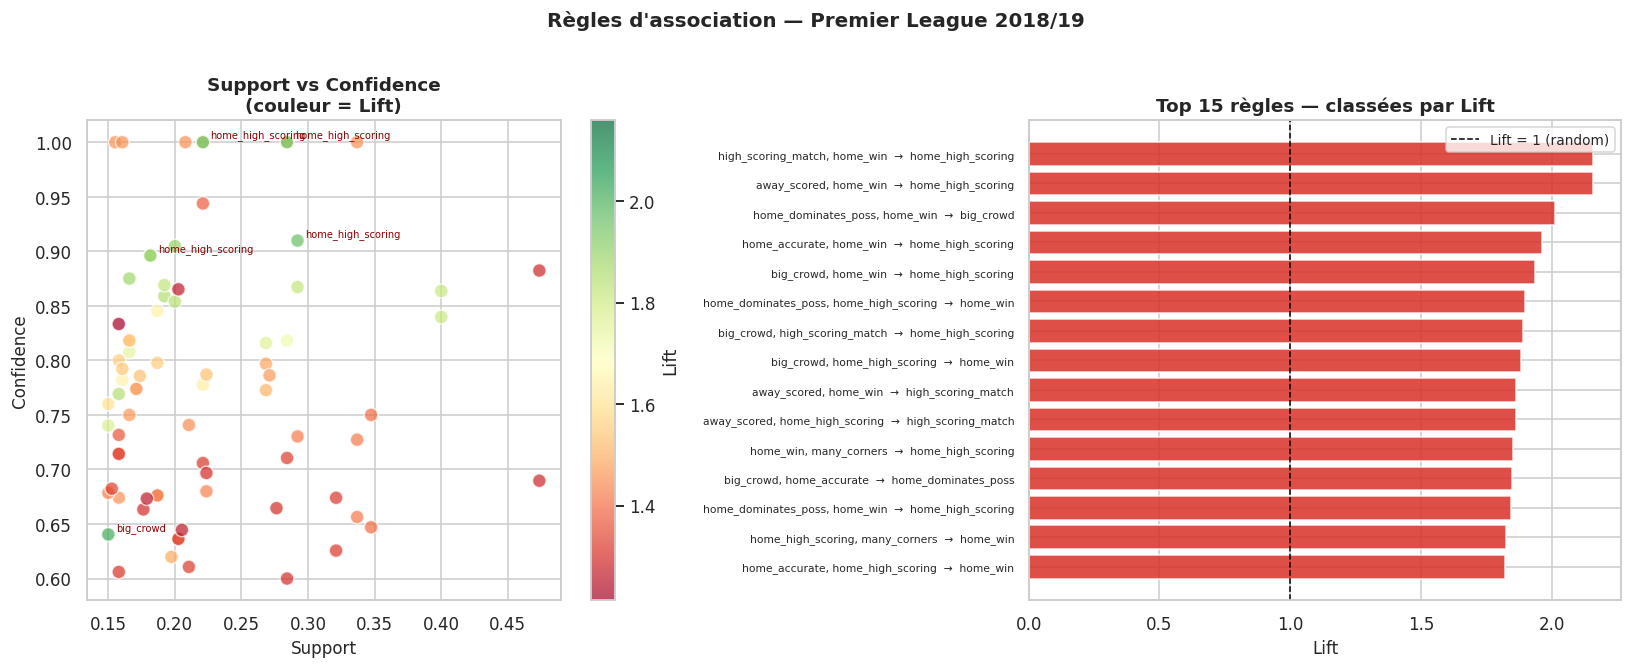

In [ ]:
# --- Visualization 1: Scatter plot Support vs Confidence colored by Lift ---
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

scatter = axes[0].scatter(
    strong_rules['support'],
    strong_rules['confidence'],
    c=strong_rules['lift'],
    cmap='RdYlGn',
    s=80, alpha=0.7, edgecolors='white'
)
plt.colorbar(scatter, ax=axes[0], label='Lift')
axes[0].set_xlabel('Support', fontsize=11)
axes[0].set_ylabel('Confidence', fontsize=11)
axes[0].set_title('Support vs Confidence\n(couleur = Lift)', fontweight='bold')

# Annotate top 5 rules by lift
top5 = strong_rules.nlargest(5, 'lift')
for _, row in top5.iterrows():
    axes[0].annotate(
        f"{row['consequents_str']}",
        (row['support'], row['confidence']),
        fontsize=6.5, ha='left',
        xytext=(5, 3), textcoords='offset points',
        color='darkred'
    )

# --- Visualization 2: Top 15 rules by lift - horizontal bar ---
top15 = strong_rules.nlargest(15, 'lift').copy()
top15['rule'] = top15['antecedents_str'] + '  →  ' + top15['consequents_str']
top15 = top15.sort_values('lift')

colors = ['#d73027' if l > 1.8 else '#fc8d59' if l > 1.5 else '#91cf60'
          for l in top15['lift']]

axes[1].barh(top15['rule'], top15['lift'],
             color=colors, edgecolor='white', alpha=0.85)
axes[1].axvline(1.0, color='black', linestyle='--', linewidth=1, label='Lift = 1 (random)')
axes[1].set_xlabel('Lift', fontsize=11)
axes[1].set_title('Top 15 règles — classées par Lift', fontweight='bold')
axes[1].tick_params(axis='y', labelsize=7)
axes[1].legend(fontsize=9)

plt.suptitle("Règles d'association — Premier League 2018/19",
             fontsize=13, fontweight='bold', y=1.01)
plt.tight_layout()
plt.show()

### 7.6 Heatmap de confiance

La heatmap croise les **antécédents** (lignes) et les **conséquents** (colonnes) des 20 meilleures règles. La couleur représente la confiance — plus la cellule est sombre, plus la règle est fiable. Les cellules blanches indiquent une combinaison absente du top 20.

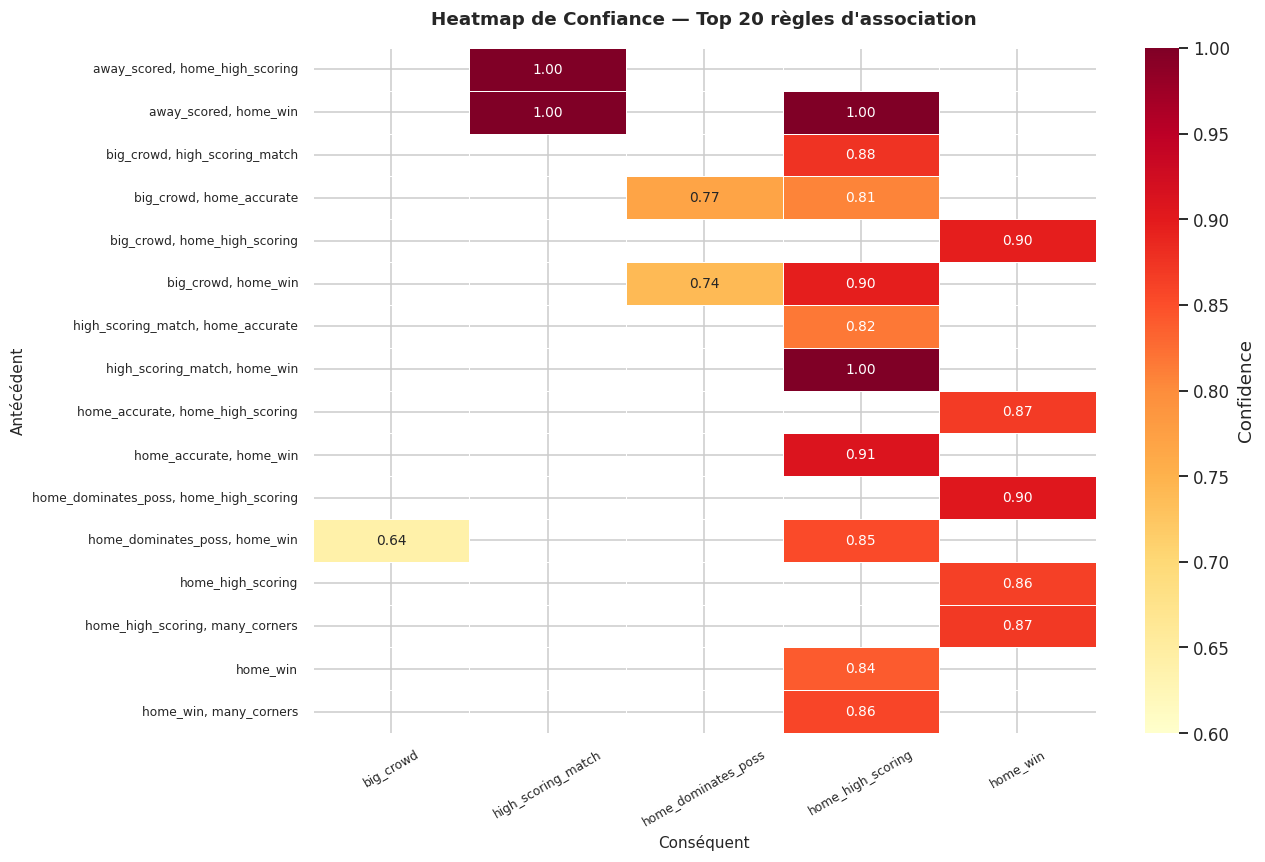

In [ ]:
# --- Visualization 3: Confidence heatmap top rules ---
top20 = strong_rules.nlargest(20, 'lift')[
    ['antecedents_str','consequents_str','confidence','lift','support']
].copy()

# Pivot for heatmap — unique antecedents vs consequents
pivot = top20.pivot_table(
    index='antecedents_str',
    columns='consequents_str',
    values='confidence',
    aggfunc='max'
)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(
    pivot, annot=True, fmt='.2f',
    cmap='YlOrRd', linewidths=0.5,
    ax=ax, vmin=0.6, vmax=1.0,
    annot_kws={'size': 9},
    cbar_kws={'label': 'Confidence'}
)
ax.set_title("Heatmap de Confiance — Top 20 règles d'association",
             fontweight='bold', fontsize=12, pad=15)
ax.set_xlabel('Conséquent', fontsize=10)
ax.set_ylabel('Antécédent', fontsize=10)
ax.tick_params(axis='x', rotation=30, labelsize=8)
ax.tick_params(axis='y', rotation=0, labelsize=8)
plt.tight_layout()
plt.show()

### 7.7 Résumé et interprétation

Les règles sont triées par **lift décroissant** pour mettre en avant les associations les plus informatives. On distingue quatre groupes de patterns :

| Groupe | Description |
|--------|-------------|
| 🔵 **Chaîne offensive** | précision des tirs → buts → victoire domicile |
| 🔴 **Confiance absolue** | règles vérifiées dans 100 % des cas (conf = 1.0) |
| 🟡 **Effet du public** | grandes affluences → meilleures performances à domicile |
| 🟢 **Matchs ouverts** | matchs intenses + prolifiques → l'équipe extérieure marque |

In [ ]:
# --- Final clean summary ---
print("=" * 90)
print("TOP 10 RÈGLES D'ASSOCIATION — Premier League 2018/19")
print("=" * 90)
print(f"{'#':<4} {'Antécédent':<45} {'Conséquent':<22} {'Sup':>6} {'Conf':>6} {'Lift':>6}")
print("-" * 90)

for i, (_, row) in enumerate(strong_rules.nlargest(10, 'lift').iterrows(), 1):
    print(f"{i:<4} {row['antecedents_str']:<45} {row['consequents_str']:<22} "
          f"{row['support']:>6.3f} {row['confidence']:>6.3f} {row['lift']:>6.3f}")

print("=" * 90)
print(f"\nTotal règles générées        : 236")
print(f"Règles fortes retenues       : {len(strong_rules)}")
print(f"Lift max                     : {strong_rules['lift'].max():.3f}")
print(f"Confidence moyenne (fortes)  : {strong_rules['confidence'].mean():.3f}")

TOP 10 RÈGLES D'ASSOCIATION — Premier League 2018/19
#    Antécédent                                    Conséquent                Sup   Conf   Lift
------------------------------------------------------------------------------------------
1    away_scored, home_win                         home_high_scoring       0.221  1.000  2.159
2    high_scoring_match, home_win                  home_high_scoring       0.284  1.000  2.159
3    home_dominates_poss, home_win                 big_crowd               0.150  0.640  2.011
4    home_accurate, home_win                       home_high_scoring       0.292  0.910  1.964
5    big_crowd, home_win                           home_high_scoring       0.182  0.896  1.935
6    home_dominates_poss, home_high_scoring        home_win                0.200  0.905  1.900
7    big_crowd, high_scoring_match                 home_high_scoring       0.166  0.875  1.889
8    big_crowd, home_high_scoring                  home_win                0.182  0.896  1.881
9

---
<a id='8'></a>
## 8. 🎯 Apprentissage Supervisé — Régression Logistique

La régression logistique est utilisée pour **prédire la victoire à domicile**
et identifier les facteurs qui l'influencent le plus.

| Élément | Détail |
|---------|--------|
| **Variable cible** |
 (1 = Victoire domicile, 0 = Match nul , 2 = Victoire exterieur
) |
| **Split** | 80% train / 20% test |
| **Standardisation** | StandardScaler |
| **Métriques** | Accuracy, Precision, Recall, F1-score |

In [ ]:
# ── Cellule 1 : Préparation des données ──────────────────────────────────────
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Variable cible à 3 classes
df['result_encoded'] = df['result'].map({
    'Victoire domicile'  : 0,
    'Nul'                : 1,
    'Victoire extérieur' : 2
})

features_v2 = [
    'home_team_shots_on_target', 'away_team_shots_on_target',
    'home_team_possession',      'home_team_corner_count',
    'away_team_corner_count',    'home_team_yellow_cards',
    'away_team_yellow_cards',    'home_team_fouls',
    'away_team_fouls',           'home_team_shots',
    'away_team_shots',           'total_goal_count'
]

X = df[features_v2].dropna()
y = df.loc[X.index, 'result_encoded']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s  = scaler.transform(X_test)

print(f'✅ Train : {X_train.shape[0]} matchs | Test : {X_test.shape[0]} matchs')
print(f'Classes : {y.value_counts().to_dict()}')

✅ Train : 304 matchs | Test : 76 matchs
Classes : {0: 181, 2: 128, 1: 71}


In [ ]:
# ── Cellule 2 : Entraînement + Métriques ─────────────────────────────────────
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import cross_val_score

# Multinomial
model_lr = LogisticRegression(max_iter=1000, random_state=42)
model_lr.fit(X_train_s, y_train)
y_pred = model_lr.predict(X_test_s)

print('=== Métriques de performance ===')
print(f'Accuracy  : {accuracy_score(y_test, y_pred):.2f}')
print(f'Precision : {precision_score(y_test, y_pred, average="macro"):.2f}')
print(f'Recall    : {recall_score(y_test, y_pred, average="macro"):.2f}')
print(f'F1-score  : {f1_score(y_test, y_pred, average="macro"):.2f}')

scores = cross_val_score(model_lr, X_train_s, y_train, cv=5, scoring='accuracy')
print(f'CV Accuracy : {scores.mean():.2f} ± {scores.std():.2f}')

=== Métriques de performance ===
Accuracy  : 0.67
Precision : 0.58
Recall    : 0.58
F1-score  : 0.56
CV Accuracy : 0.60 ± 0.04


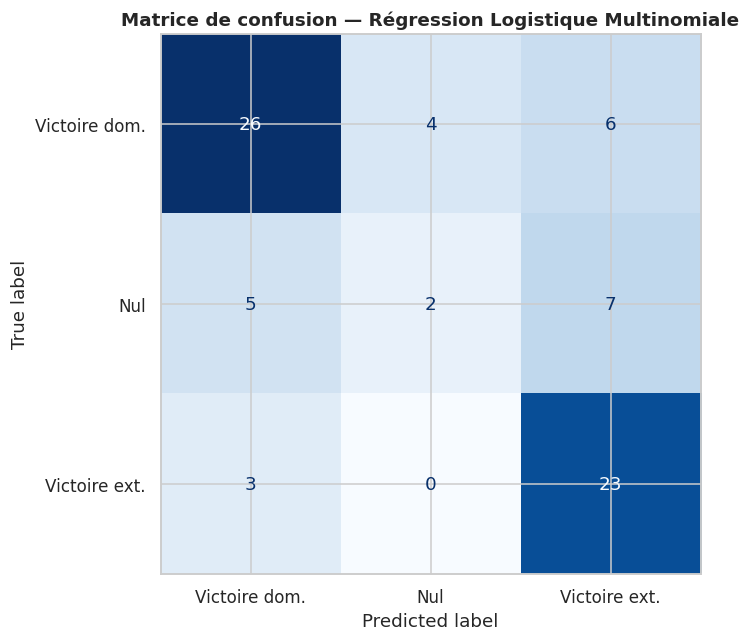

In [ ]:
# ── Cellule 3 : Matrice de confusion ─────────────────────────────────────────
from sklearn.metrics import ConfusionMatrixDisplay

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    display_labels=['Victoire dom.', 'Nul', 'Victoire ext.'],
    colorbar=False, ax=ax, cmap='Blues')
ax.set_title('Matrice de confusion — Régression Logistique Multinomiale',
             fontweight='bold')
plt.tight_layout()
plt.show()

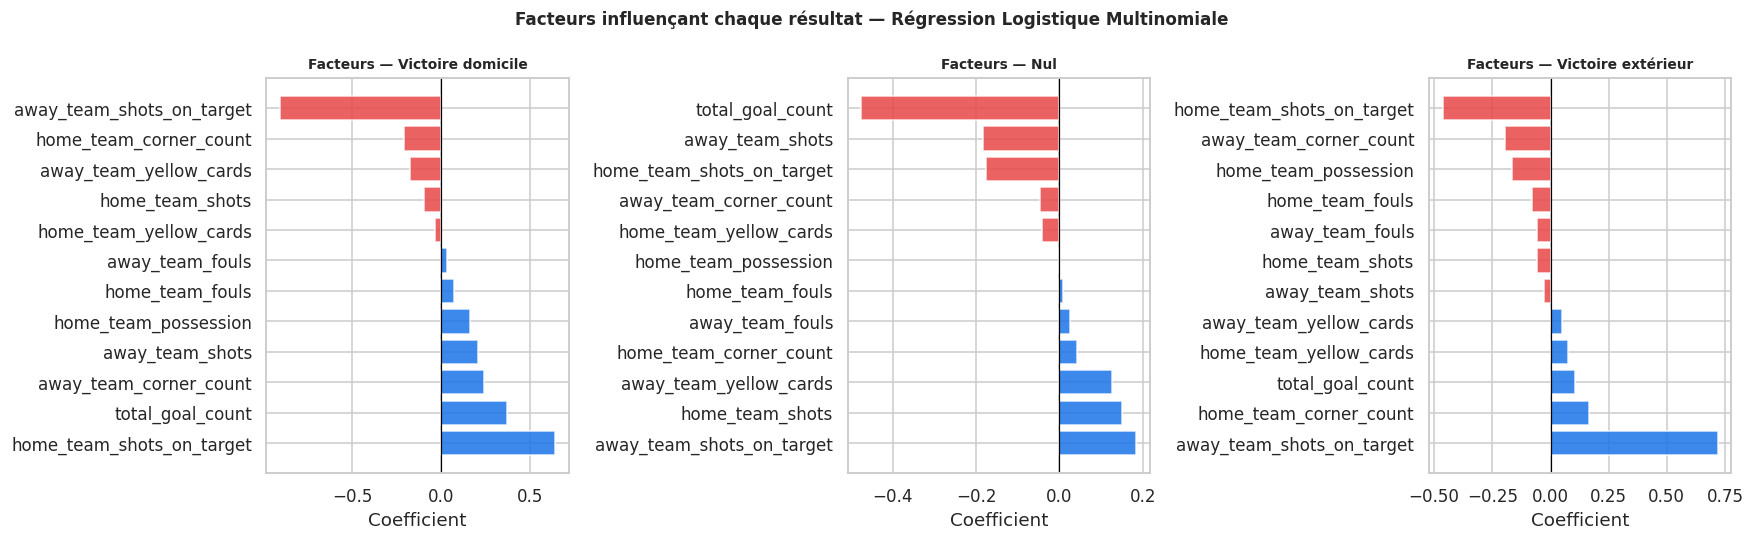

In [ ]:
# ── Cellule 4 : Coefficients par classe ──────────────────────────────────────
classes = ['Victoire domicile', 'Nul', 'Victoire extérieur']

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for i, (ax, cls) in enumerate(zip(axes, classes)):
    coef_df = pd.DataFrame({
        'Variable'   : features_v2,
        'Coefficient': model_lr.coef_[i]
    }).sort_values('Coefficient', ascending=False)

    colors = ['#1a73e8' if c > 0 else '#e84646' for c in coef_df['Coefficient']]
    ax.barh(coef_df['Variable'], coef_df['Coefficient'],
            color=colors, edgecolor='white', alpha=0.85)
    ax.axvline(0, color='black', linewidth=0.8)
    ax.set_title(f'Facteurs — {cls}', fontweight='bold', fontsize=9)
    ax.set_xlabel('Coefficient')

plt.suptitle('Facteurs influençant chaque résultat — Régression Logistique Multinomiale',
             fontweight='bold', fontsize=11)
plt.tight_layout()
plt.show()

---
<a id='9'></a>
## 9. 🎯 Apprentissage Non Supervisé — CLUSTERING K-MEANS

Le clustering K-Means est utilisé pour **regrouper les matchs selon leurs caractéristiques**
et identifier des profils de matchs similaires.

| Élément | Détail |
|---------|--------|
| **Variables utilisées** | Tirs cadrés, possession, buts, corners et cartons jaunes |
| **Standardisation** | StandardScaler |
| **Choix de K** | Méthode du coude et Score de Silhouette |
| **Nombre de clusters** | K = 3 |
| **Visualisation** | Projection PCA 2D et Heatmap des profils |

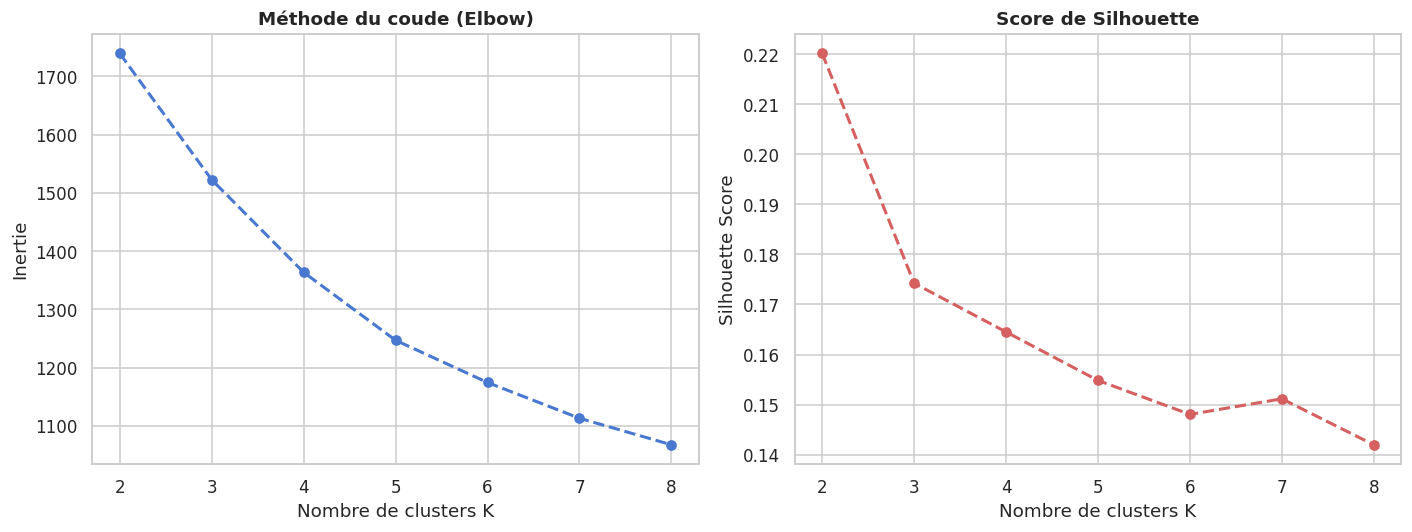

In [ ]:
# ── Cellule 1 : Préparation + Méthode du coude ───────────────────────────────
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

cluster_features = [
    'home_team_shots_on_target', 'away_team_shots_on_target',
    'home_team_possession',      'total_goal_count',
    'home_team_corner_count',    'total_yellow_cards'
]

X_clust = df[cluster_features].dropna()
scaler2 = StandardScaler()
X_clust_s = scaler2.fit_transform(X_clust)

inertia, silhouettes = [], []
K_range = range(2, 9)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X_clust_s)
    inertia.append(km.inertia_)
    silhouettes.append(silhouette_score(X_clust_s, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].plot(K_range, inertia, 'bo--', linewidth=2, markersize=6)
axes[0].set_title('Méthode du coude (Elbow)', fontweight='bold')
axes[0].set_xlabel('Nombre de clusters K')
axes[0].set_ylabel('Inertie')

axes[1].plot(K_range, silhouettes, 'ro--', linewidth=2, markersize=6)
axes[1].set_title('Score de Silhouette', fontweight='bold')
axes[1].set_xlabel('Nombre de clusters K')
axes[1].set_ylabel('Silhouette Score')
plt.tight_layout()
plt.show()

In [ ]:
# ── Cellule 2 : K-Means final (K=3) ──────────────────────────────────────────
K_OPTIMAL = 3

km_final = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
df_clust = X_clust.copy()
df_clust['Cluster'] = km_final.fit_predict(X_clust_s)

print('=== Profil moyen par cluster ===')
print(df_clust.groupby('Cluster').mean().round(2))

=== Profil moyen par cluster ===
         home_team_shots_on_target  away_team_shots_on_target  \
Cluster                                                         
0                             9.28                       4.16   
1                             5.08                       3.54   
2                             4.52                       6.38   

         home_team_possession  total_goal_count  home_team_corner_count  \
Cluster                                                                   
0                       63.37              4.30                    7.64   
1                       54.99              1.58                    6.98   
2                       41.69              3.10                    3.70   

         total_yellow_cards  
Cluster                      
0                      2.63  
1                      3.08  
2                      3.73  


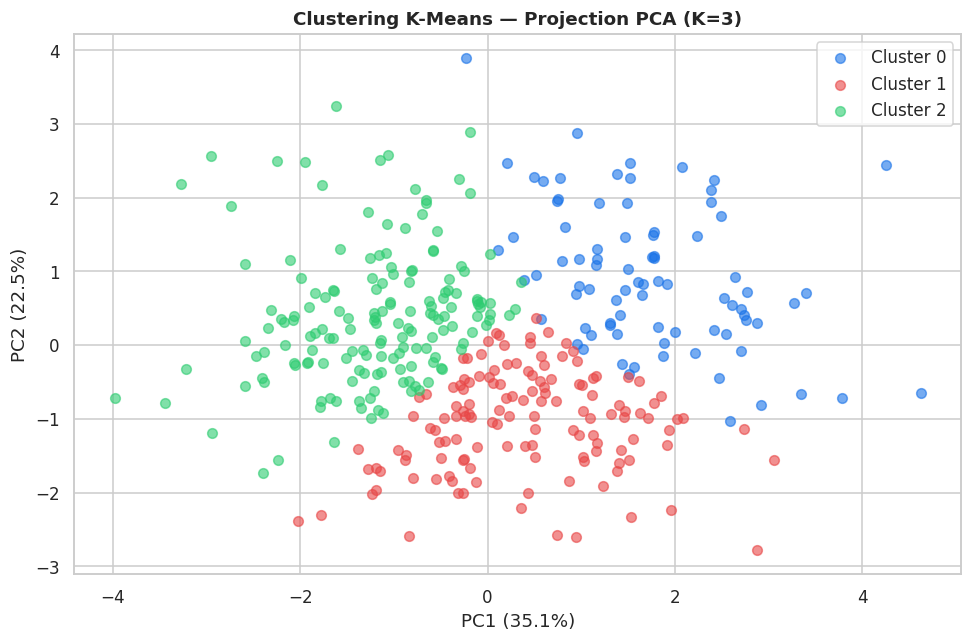

In [ ]:
# ── Cellule 3 : Projection PCA 2D ────────────────────────────────────────────
from sklearn.decomposition import PCA

pca_vis = PCA(n_components=2)
X_pca_vis = pca_vis.fit_transform(X_clust_s)

fig, ax = plt.subplots(figsize=(9, 6))
colors_c = ['#1a73e8', '#e84646', '#2ecc71']
for c in range(K_OPTIMAL):
    mask = df_clust['Cluster'] == c
    ax.scatter(X_pca_vis[mask, 0], X_pca_vis[mask, 1],
               c=colors_c[c], label=f'Cluster {c}', alpha=0.6, s=40)
ax.set_title('Clustering K-Means — Projection PCA (K=3)', fontweight='bold')
ax.set_xlabel(f'PC1 ({pca_vis.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'PC2 ({pca_vis.explained_variance_ratio_[1]*100:.1f}%)')
ax.legend()
plt.tight_layout()
plt.show()

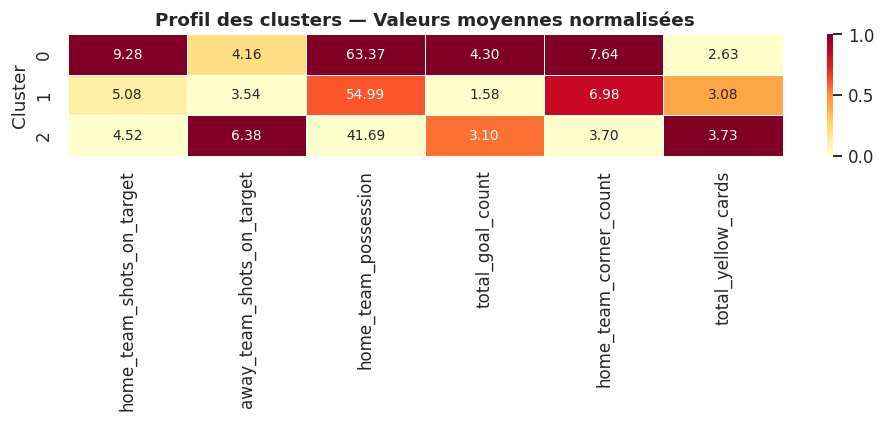

In [ ]:
# ── Cellule 4 : Heatmap profil des clusters ───────────────────────────────────
profile = df_clust.groupby('Cluster').mean()
profile_norm = (profile - profile.min()) / (profile.max() - profile.min())

fig, ax = plt.subplots(figsize=(9, 4))
sns.heatmap(profile_norm, annot=profile.round(2), fmt='.2f',
            cmap='YlOrRd', linewidths=0.5, ax=ax,
            annot_kws={'size': 9})
ax.set_title('Profil des clusters — Valeurs moyennes normalisées',
             fontweight='bold')
plt.tight_layout()
plt.show()